# Qué conservan los embeddings cuando una canción habla de miedo

**Cuaderno de investigación en español · corte del corpus: 11 de octubre de 2026.**

Una canción puede nombrar el miedo y negarlo. Puede ocultar una amenaza bajo una celebración, prestar su voz a un personaje o volver al mismo estribillo sin resolver nada. Una representación útil debería ayudarnos a examinar esas diferencias. Un mapa atractivo puede ocultarlas.

Este estudio reúne 40 casos en inglés y español desde los años ochenta, contrasta proveedores de letras, compara dos encoders locales y embeddings de OpenAI, estima tópicos con BERTopic y evalúa recuperación con contexto mediante LangGraph. Los resultados corresponden a corridas reales locales. OpenAI se ejecutó sobre el corpus autorizado; Anthropic revisó frases sintéticas originales. Gemini devolvió HTTP 402 y no aporta vectores.

La pregunta central es qué conserva y qué pierde cada representación cuando tratamos de interpretar el miedo. La pregunta histórica queda condicionada a estas canciones elegidas: no podemos inferir una evolución poblacional de la música popular con cuatro canciones por idioma y período.

## 1. El contrato de lectura

Distingo cinco objetos que suelen acabar comprimidos en un único color:

| Objeto | Pregunta | Evidencia necesaria |
|---|---|---|
| Tópico | ¿De qué situación se habla? | Pasajes relacionados y contraejemplos |
| Emoción expresada | ¿Quién teme qué? | Experienciador, objeto, negación y contexto |
| Postura | ¿Qué hace la voz frente a eso? | Evitación, confrontación, cuidado o ambivalencia |
| Trayectoria afectiva | ¿Cómo cambia una medida dentro del texto? | Medida validada y unidades comparables |
| Arco argumental o narrativo | ¿Qué posición cambia y por qué? | Eventos, voces, relaciones, resistencia y desenlace |

El artista, la voz de la canción y el oyente no son intercambiables. Tampoco lo son proximidad semántica e intensidad emocional. Este cuaderno trabaja con letras: no mide armonía, timbre, ritmo, interpretación vocal ni respuesta de oyentes.

La claridad visual de [The Illustrated Word2vec](https://jalammar.github.io/illustrated-word2vec/) inspira la explicación gradual: texto, vector, vecindad y decisiones observables. La escritura y las figuras de este estudio son originales.

In [1]:
from pathlib import Path
import json, os, sys, subprocess, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

# Funciona al abrir desde la raíz o desde research/fear-lyrics.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'research/fear-lyrics/analyze.py').exists())
STUDY = ROOT/'research/fear-lyrics'
RESULTS = STUDY/'results'
PRIVATE = ROOT/'.research-cache/fear-lyrics'
read = lambda p: json.loads(p.read_text())

# False lee las corridas guardadas: abrir el notebook no descarga letras ni llama APIs.
# True vuelve a calcular los experimentos desde el corpus privado y pesos ya descargados.
RERUN_EXPERIMENTS = os.environ.get('RERUN_FEAR_EXPERIMENTS') == '1'
if RERUN_EXPERIMENTS:
    subprocess.run([sys.executable, str(STUDY/'analyze.py'), '--offline', '--model-cache', str(PRIVATE/'model-cache'), '--export-embedding-input', str(PRIVATE/'embedding-input.json')], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(STUDY/'rag.py'), '--model-cache', str(PRIVATE/'model-cache')], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(STUDY/'rag.py'), '--model-cache', str(PRIVATE/'model-cache'), '--model', 'intfloat/multilingual-e5-small', '--output', str(RESULTS/'rag-e5')], cwd=ROOT, check=True)
    if (PRIVATE/'openai-large.npz').exists():
        subprocess.run([sys.executable, str(STUDY/'analyze.py'), '--offline', '--embedding-file', str(PRIVATE/'openai-large.npz'), '--embedding-metadata', str(PRIVATE/'openai-large.json'), '--model-label', 'openai/text-embedding-3-large'], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(STUDY/'bayes.py'), '--models', 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', 'intfloat/multilingual-e5-small', 'openai/text-embedding-3-large'], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(STUDY/'evaluate.py')], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(STUDY/'visualize.py')], cwd=ROOT, check=True)
    subprocess.run([sys.executable, str(STUDY/'atlas_v2.py')], cwd=ROOT, check=True)
manifest = pd.DataFrame(read(STUDY/'corpus-manifest.json'))
diag = read(RESULTS/'corpus_diagnostics.json')
modeldirs = sorted(p for p in RESULTS.iterdir() if p.is_dir() and (p/'model_manifest.json').exists())
assert len(manifest) == 40 and len(modeldirs) >= 2
print('Corpus:', diag['songs_with_lyrics'], 'canciones |', diag['artists'], 'artistas')
print('Corridas guardadas ejecutadas: MiniLM, E5 y OpenAI; revisión OpenAI y controles Anthropic.')

Corpus: 40 canciones | 34 artistas
Corridas guardadas ejecutadas: MiniLM, E5 y OpenAI; revisión OpenAI y controles Anthropic.


## 2. Construir casos sin fabricar una historia de las décadas

El diseño es una serie de casos intencional, con cinco bloques: 1980s, 1990s, 2000s, 2010s y 2020–2026 parcial. Cada bloque tiene cuatro canciones EN y cuatro ES. Se incluyen hipótesis de miedo, casos ambiguos y controles de otros temas. Esas etiquetas se formularon para seleccionar material y **no son un gold emocional** ni entran en el índice de recuperación.

Se conserva el año de primera publicación de la grabación, separado del año de éxito en listas. Por eso *Llamando a la Tierra* pertenece a 1999 aunque su éxito en LOS40 se documenta en 2000; *Crawling* pertenece al álbum de 2000, no a su sencillo de 2001. *Aperture* representa una publicación de enero de 2026, no una muestra de todo ese año.

La evidencia comercial es heterogénea: fuentes de listas, una certificación y algunos casos de alcance documentado sin ranking comparable. Una canción popular en un país o momento no proporciona una escala universal de éxito. El equilibrio de idiomas tampoco iguala géneros, países, sexo de las voces, industria ni distribución de las situaciones de miedo.

In [2]:
display(manifest.groupby(['decade','language']).size().unstack().rename(columns={'en':'Inglés','es':'Español'}))
display(manifest[['title','artist','year','language','selection_label']])
display(Markdown('Las etiquetas de la tabla son hipótesis de selección del analista, no anotaciones validadas.'))

language,Inglés,Español
decade,,
1980,4,4
1990,4,4
2000,4,4
2010,4,4
2020,4,4


,title,artist,year,language,selection_label
0,Thriller,Michael Jackson,1982,en,fear
1,Mad World,Tears for Fears,1982,en,ambiguous
2,Somebody's Watching Me,Rockwell,1983,en,fear
3,Wake Me Up Before You Go-Go,Wham!,1984,en,control
4,En algún lugar,Duncan Dhu,1987,es,ambiguous
5,Hijo de la Luna,Mecano,1986,es,ambiguous
6,Cruz de Navajas,Mecano,1986,es,ambiguous
7,Bailando,Alaska y los Pegamoides,1982,es,control
8,Enter Sandman,Metallica,1991,en,fear
9,Zombie,The Cranberries,1994,en,fear


Las etiquetas de la tabla son hipótesis de selección del analista, no anotaciones validadas.

## 3. Un proveedor también es una decisión de medida

LRCLIB, Genius/LyricsGenius y lyrics.ovh se consultaron sobre el mismo manifiesto. Una respuesta disponible no demuestra que la edición sea correcta. Comparo identidad de artista y título, metadatos de edición, hashes, conteos y similitud de texto normalizado. El acuerdo no garantiza independencia entre fuentes.

Hay una diferencia técnica relevante: [LyricsGenius](https://lyricsgenius.readthedocs.io/en/master/how_it_works.html) usa la API de Genius para metadatos y búsqueda; la letra se extrae de la página. No es un endpoint oficial de descarga de letras. Las letras y respuestas quedan en caché privada, fuera del repositorio público. El material distribuido contiene referencias y resultados, no el corpus textual.

La auditoría se hace antes de representar: retirar timestamps LRC no equivale a borrar el significado; elegir una versión de estudio frente a *Unplugged* sí cambia qué objeto estamos estudiando. Los cambios se conservan en el registro de auditoría.

,consultadas,disponibles
provider,,
genius,40,34
lrclib,40,39
ovh,40,0


,,pares,mediana_similitud,mínimo,idénticas
provider_a,provider_b,,,,
lrclib,genius,33,0.935897,0.559025,0


Auditoría de fuentes guardada en `source-audit.json`; no se imprimen letras.

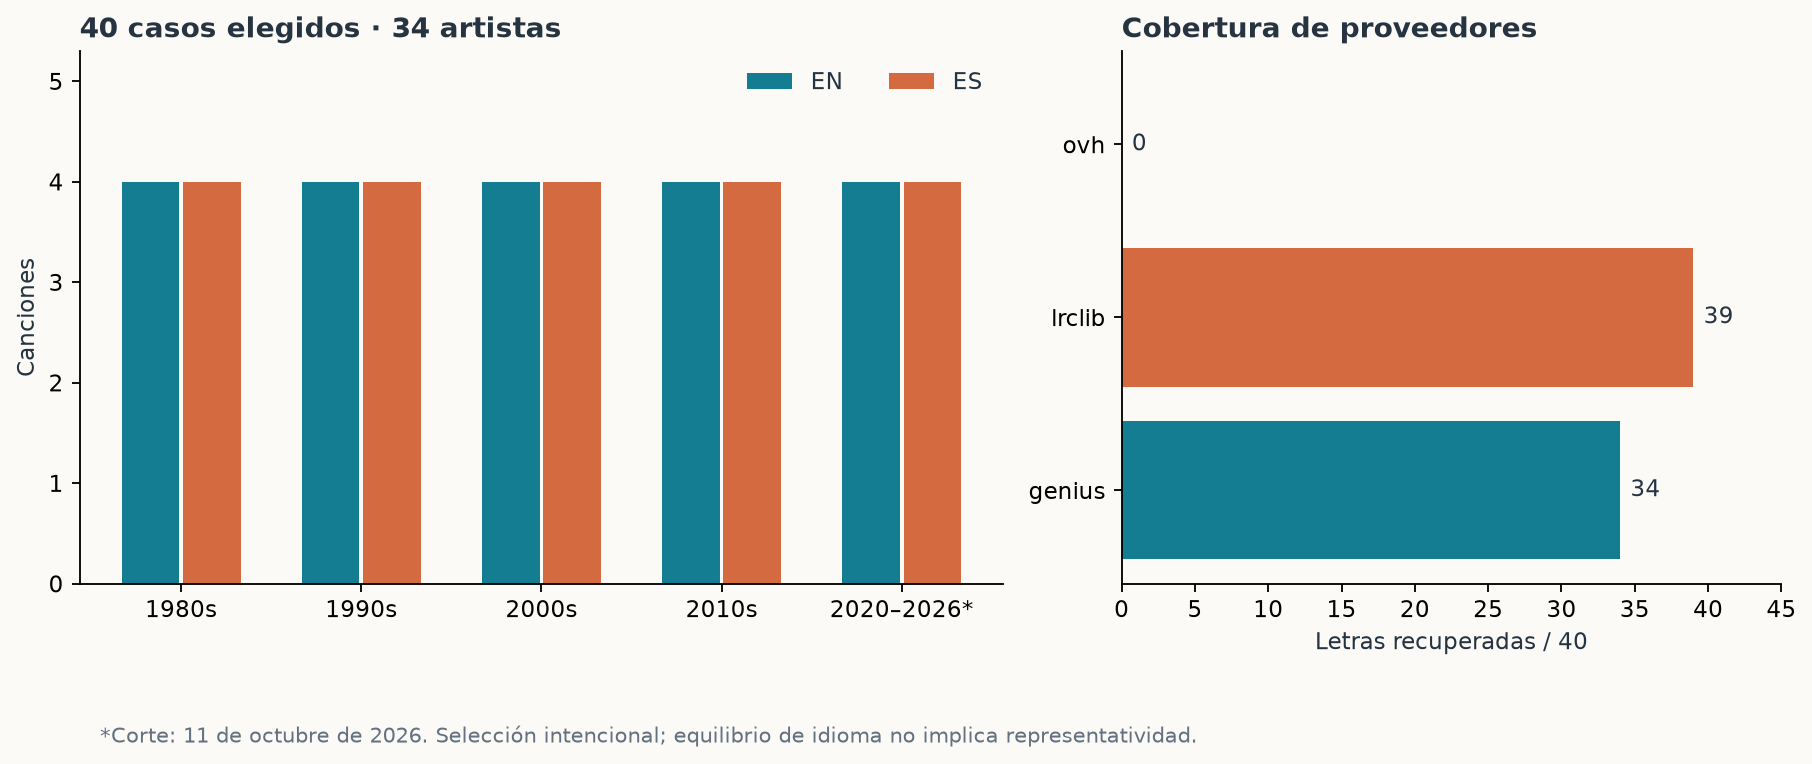

In [3]:
coverage = pd.read_csv(STUDY/'provider-coverage.csv')
agreement = pd.read_csv(STUDY/'provider-agreement.csv')
display(coverage.assign(available=coverage.status.astype(str).eq('200')).groupby('provider').agg(
    consultadas=('song_id','size'), disponibles=('available','sum')))
display(agreement.groupby(['provider_a','provider_b']).agg(
    pares=('song_id','size'), mediana_similitud=('sequence_similarity','median'),
    mínimo=('sequence_similarity','min'), idénticas=('normalized_exact_match','sum')))
auditfile = STUDY/'source-audit.json'
if auditfile.exists(): display(Markdown('Auditoría de fuentes guardada en `source-audit.json`; no se imprimen letras.'))
display(Image(filename=str(STUDY/'figures/corpus-providers.png')))

## 4. La unidad es un bloque; la independencia es una canción

Se preservan párrafos, orden, pronombres y negaciones. Los párrafos largos se dividen en ventanas de un máximo de ocho líneas. Cuando el proveedor no delimita estrofas, hablamos de **ventanas**, no de unidades musicales verificadas.

Los bloques repetidos exactamente dentro de una canción se deduplican para descubrir tópicos. Para las trayectorias se conservan dos variantes: primera aparición y todos los bloques. Una repetición parcial puede sobrevivir a la deduplicación exacta. Una canción puede aportar más vocabulario que otra, de modo que el ajuste global aún recibe longitudes diferentes. Las proporciones y sus intervalos se calculan por canción para evitar convertir versos dependientes en cientos de observaciones independientes.

Los intervalos bootstrap remuestrean canciones dentro de idioma, con 1.000 muestras y pesos iguales EN/ES. Describen sensibilidad del corpus escogido. No corrigen el sesgo de selección ni convierten 40 canciones en una muestra representativa.

In [4]:
display(pd.Series({k:diag[k] for k in ['blocks','unique_blocks','exact_repeated_blocks','cutoff','corpus_identity']}))
inventory = pd.read_csv(RESULTS/'section_inventory.csv')
assert inventory.document_id.is_unique
print('Se preservan IDs de bloque, orden, tipo de segmentación y conteos; no se publica texto.')

blocks                                                                 461
unique_blocks                                                          386
exact_repeated_blocks                                                   75
cutoff                                                          2026-10-11
corpus_identity          d10938991b3994c9b7cd413eb5a235668523bf629311d6...
dtype: object

Se preservan IDs de bloque, orden, tipo de segmentación y conteos; no se publica texto.


## 5. Dos encoders, tareas y ventanas diferentes

[MiniLM multilingüe](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2) ofrece una representación general de frases. [E5 small multilingüe](https://huggingface.co/intfloat/multilingual-e5-small) requiere distinguir `query:` de `passage:` y responde a un entrenamiento de recuperación. Ambos producen vectores de 384 dimensiones, pero eso no hace equivalentes sus espacios.

Las similitudes se calculan con normalización L2 dentro de cada modelo. Se comparan decisiones de ranking, particiones y sensibilidad, no se interpreta que 0.8 en uno signifique más miedo que 0.6 en otro. Se registra el límite real de tokens y los bloques que lo exceden. Un último verso fuera de ventana puede desaparecer aunque el notebook muestre la canción completa en el manifiesto.

El adaptador `embed_api.py` ejecutó OpenAI con 1.024 dimensiones. Gemini reconoció la clave al listar modelos, pero devolvió HTTP 402 por facturación/crédito en inferencia. Los resultados alojados se identifican como una extensión posterior a las dos corridas locales. Un proveedor de letras y un proveedor de embeddings resuelven problemas distintos. Las APIs se ejecutan únicamente con flags explícitos; abrir este cuaderno usa resultados guardados.

In [5]:
models = []
for directory in modeldirs:
    receipt = read(directory/'model_manifest.json')
    encoder = receipt['encoder']
    models.append({'modelo':encoder['model_id'], 'dimensiones':encoder.get('dimensions',384),
                   'ventana_tokens':encoder['max_seq_length'], 'bloques_truncados':receipt['truncated_documents'],
                   'segundos_corrida':receipt['runtime_seconds'], 'estado':receipt['results_status']})
display(pd.DataFrame(models))

,modelo,dimensiones,ventana_tokens,bloques_truncados,segundos_corrida,estado
0,intfloat/multilingual-e5-small,384,512,0,2.40,executed
1,openai/text-embedding-3-large,1024,8192,0,16.07,executed
2,sentence-transformers/paraphrase-multilingual-...,384,128,2,12.20,executed


## 6. Contrastes controlados antes de interpretar canciones

La negación, la inversión de roles y el orden son buenos lugares para desconfiar de una semejanza cómoda. [ALIGN-SIM](https://aclanthology.org/2024.findings-emnlp.436/) y [Sentence Smith](https://aclanthology.org/2025.emnlp-main.1343/) motivan diagnósticos por transformaciones semánticas concretas. Aquí las frases son originales y asistidaes; no reproducimos sus benchmarks.

Veinte tripletas EN/ES prueban traducción, paráfrasis, contexto del miedo, motivos de esconderse, experienciador, negación, roles, repetición, orden y truncación. Para los contrastes con intención semántica explícita se observa el margen de ranking. Para negación y reversión de roles se informa cercanía sin tratar un coseno bajo como una supuesta etiqueta correcta. Son controles pequeños que localizan fallos posibles; no estiman exactitud sobre canciones reales.

La prueba larga conserva el prefijo y cambia el final después de la ventana. El control de orden conserva las mismas palabras con secuencias incompatibles. Son dos problemas diferentes: pérdida literal por truncación y pérdida de relaciones por agregación.

,model,id,category,related_cosine,contrast_cosine,related_minus_contrast,preferred_context_ranks_first
0,intfloat--multilingual-e5-small,negation_en,negation,0.909232,0.818072,0.091160,None
1,intfloat--multilingual-e5-small,negation_es,negation,0.917552,0.844038,0.073513,None
2,intfloat--multilingual-e5-small,role_en,role_reversal,0.989925,0.931676,0.058249,None
3,intfloat--multilingual-e5-small,role_es,role_reversal,0.990926,0.944916,0.046011,None
4,intfloat--multilingual-e5-small,translation_en_es,crosslingual,0.872449,0.749441,0.123009,True
5,intfloat--multilingual-e5-small,translation_es_en,crosslingual,0.900691,0.778456,0.122236,True
6,intfloat--multilingual-e5-small,context_en,fear_context,0.891018,0.853612,0.037405,True
7,intfloat--multilingual-e5-small,context_es,fear_context,0.882917,0.841148,0.041768,True
8,intfloat--multilingual-e5-small,repetition_en,repetition,0.898800,0.862182,0.036618,None
9,intfloat--multilingual-e5-small,repetition_es,repetition,0.927730,0.908125,0.019605,None


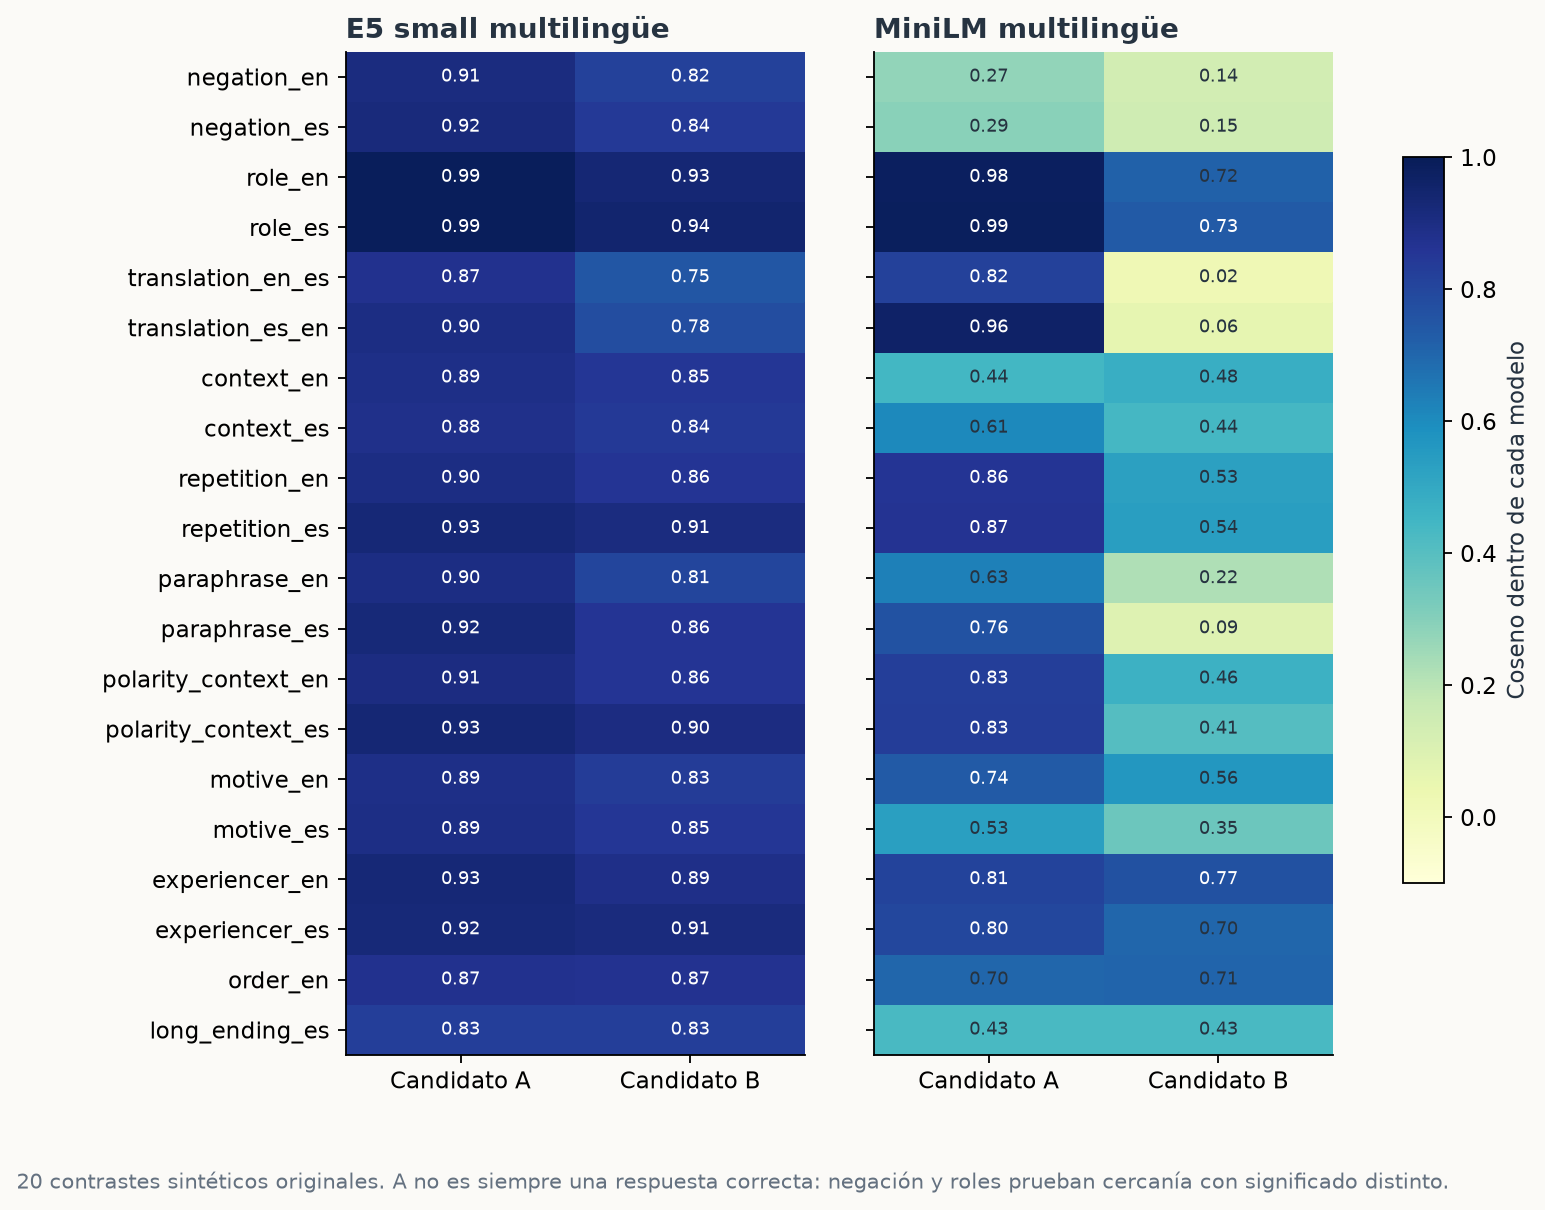

,model,id,related_cosine,contrast_cosine,query_tokenizer_tokens,query_exceeds_max_seq_length
18,intfloat--multilingual-e5-small,order_en,0.872257,0.870207,17,False
19,intfloat--multilingual-e5-small,long_ending_es,0.827470,0.827470,23,False
18,openai--text-embedding-3-large,order_en,0.593852,0.573098,10,False
19,openai--text-embedding-3-large,long_ending_es,0.574142,0.525621,21,False
18,sentence-transformers--paraphrase-multilingual...,order_en,0.699892,0.706110,15,False
19,sentence-transformers--paraphrase-multilingual...,long_ending_es,0.430526,0.430526,21,False


In [6]:
probes = pd.concat([pd.DataFrame(read(p/'semantic_probes.json')['probes']).assign(model=p.name) for p in modeldirs])
display(probes[['model','id','category','related_cosine','contrast_cosine','related_minus_contrast','preferred_context_ranks_first']])
display(Image(filename=str(STUDY/'figures/semantic-probes.png')))
display(probes[probes.category.isin(['narrative_order','long_ending'])][
    ['model','id','related_cosine','contrast_cosine','query_tokenizer_tokens','query_exceeds_max_seq_length']])

## 7. BERTopic propone vecindades; el lector examina subtemas

[BERTopic](https://arxiv.org/abs/2203.05794) combina embeddings, reducción UMAP, clustering de densidad HDBSCAN y descriptores c-TF-IDF. Ajustamos una vez sobre todos los bloques únicos de cada modelo. Los parámetros se fijan antes de observar resultados: UMAP 5D, vecinos 15, HDBSCAN mínimo de ocho bloques y tres muestras, semillas 17/42/73. El mapa 2D usa una proyección separada y no interviene en los clusters.

Un tópico puede reflejar vocabulario, idioma, una canción muy distintiva o un motivo transversal. El ruido `-1` permanece visible. La [jerarquía](https://maartengr.github.io/BERTopic/getting_started/hierarchicaltopics/hierarchicaltopics.html) agrupa por similitud de representación; no demuestra que sus ramas sean categorías literarias naturales. Las palabras automáticas se muestran como palabras, sin rebautizarlas silenciosamente como emociones.

Para hablar de un subtema del miedo proponemos una segunda capa de lectura: **amenaza externa, pérdida anticipada, exposición social, miedo a la propia conducta y afrontamiento** son ejes de anotación, no descubrimientos confirmados por el clustering. Cada lectura requiere quién habla, a qué se enfrenta, qué pasajes la sostienen y qué la contradice. Puede recibir múltiples etiquetas o quedar indeterminada.

Fichas propuestas por el asistente: `interpretive-cards.json`, sin validación humana. No constituyen gold ni etiquetas de clusters.

,canción,subtema_propuesto,límite
0,Thriller,Horror escenificado y amenaza sobrenatural,"No se incorporan el cortometraje, la interpret..."
1,Somebody's Watching Me,Vigilancia cotidiana y pérdida de privacidad,"La instrumentación, los cambios de voz y el hu..."
2,Zombie,"Violencia colectiva, duelo y persistencia del ...",La metáfora del título no debe equipararse a l...
3,Miedo,"Ruptura, culpa y temor a la ausencia o al reen...",Las explicaciones posteriores de los composito...
4,Crawling,Pérdida de control y extrañeza del propio cuerpo,No se leen como evidencia diagnóstica ni la bi...
5,Out Of The Woods,Inseguridad relacional y búsqueda reiterada de...,No se usa el videoclip para decidir la direcci...
6,Malamente,"Presagio adverso, incertidumbre y afirmación d...","Se trata de la letra de esta canción, no del a..."
7,La Puerta Violeta,"Opresión, silencio impuesto y reconstrucción d...",La contextualización pública de la canción com...
8,Color Esperanza,Respuesta al temor mediante exhortación y posi...,La etiqueta de selección fear solo conservó el...
9,Your Power,"Asimetría de poder, vulnerabilidad y responsab...",No se identifica al destinatario con una perso...


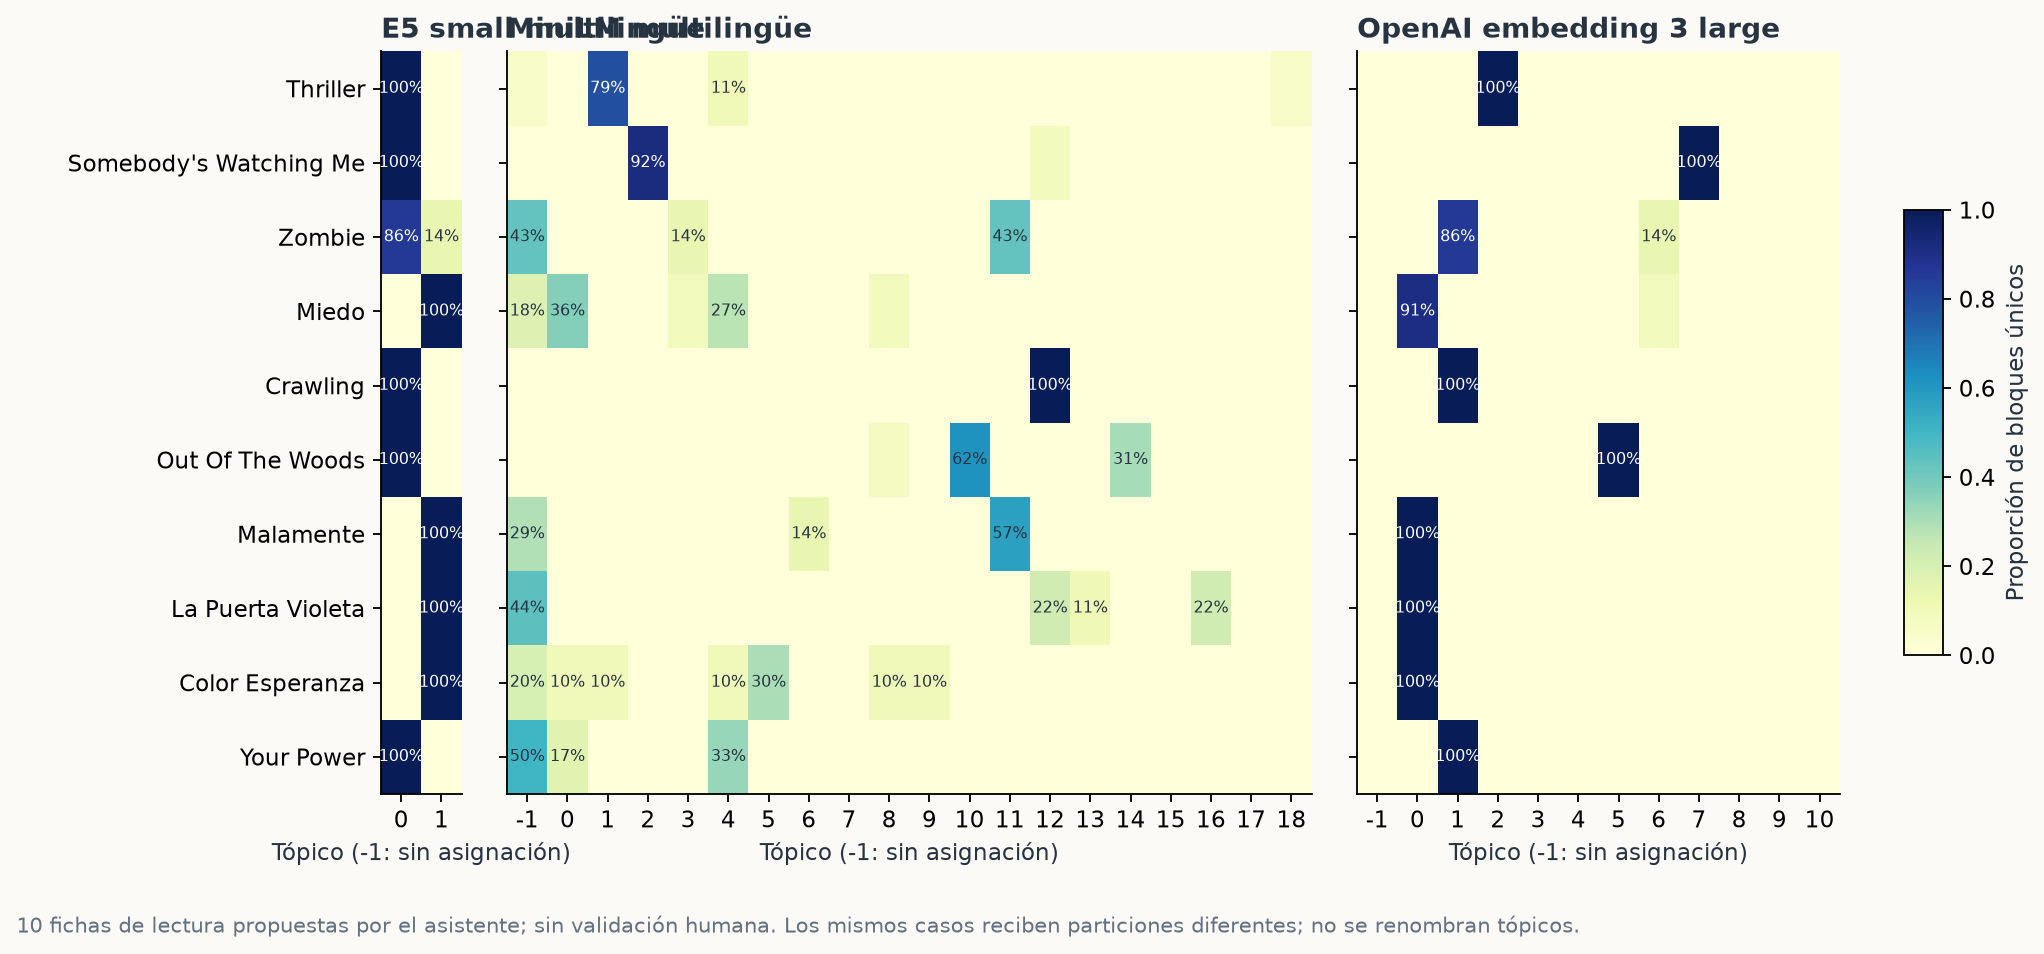

### intfloat--multilingual-e5-small

,tópico,bloques,canciones,palabras
0,0,196,20,like · it's · wanna · now · got · don't
1,1,190,26,no · mama · mama mama · uh · mal · matador


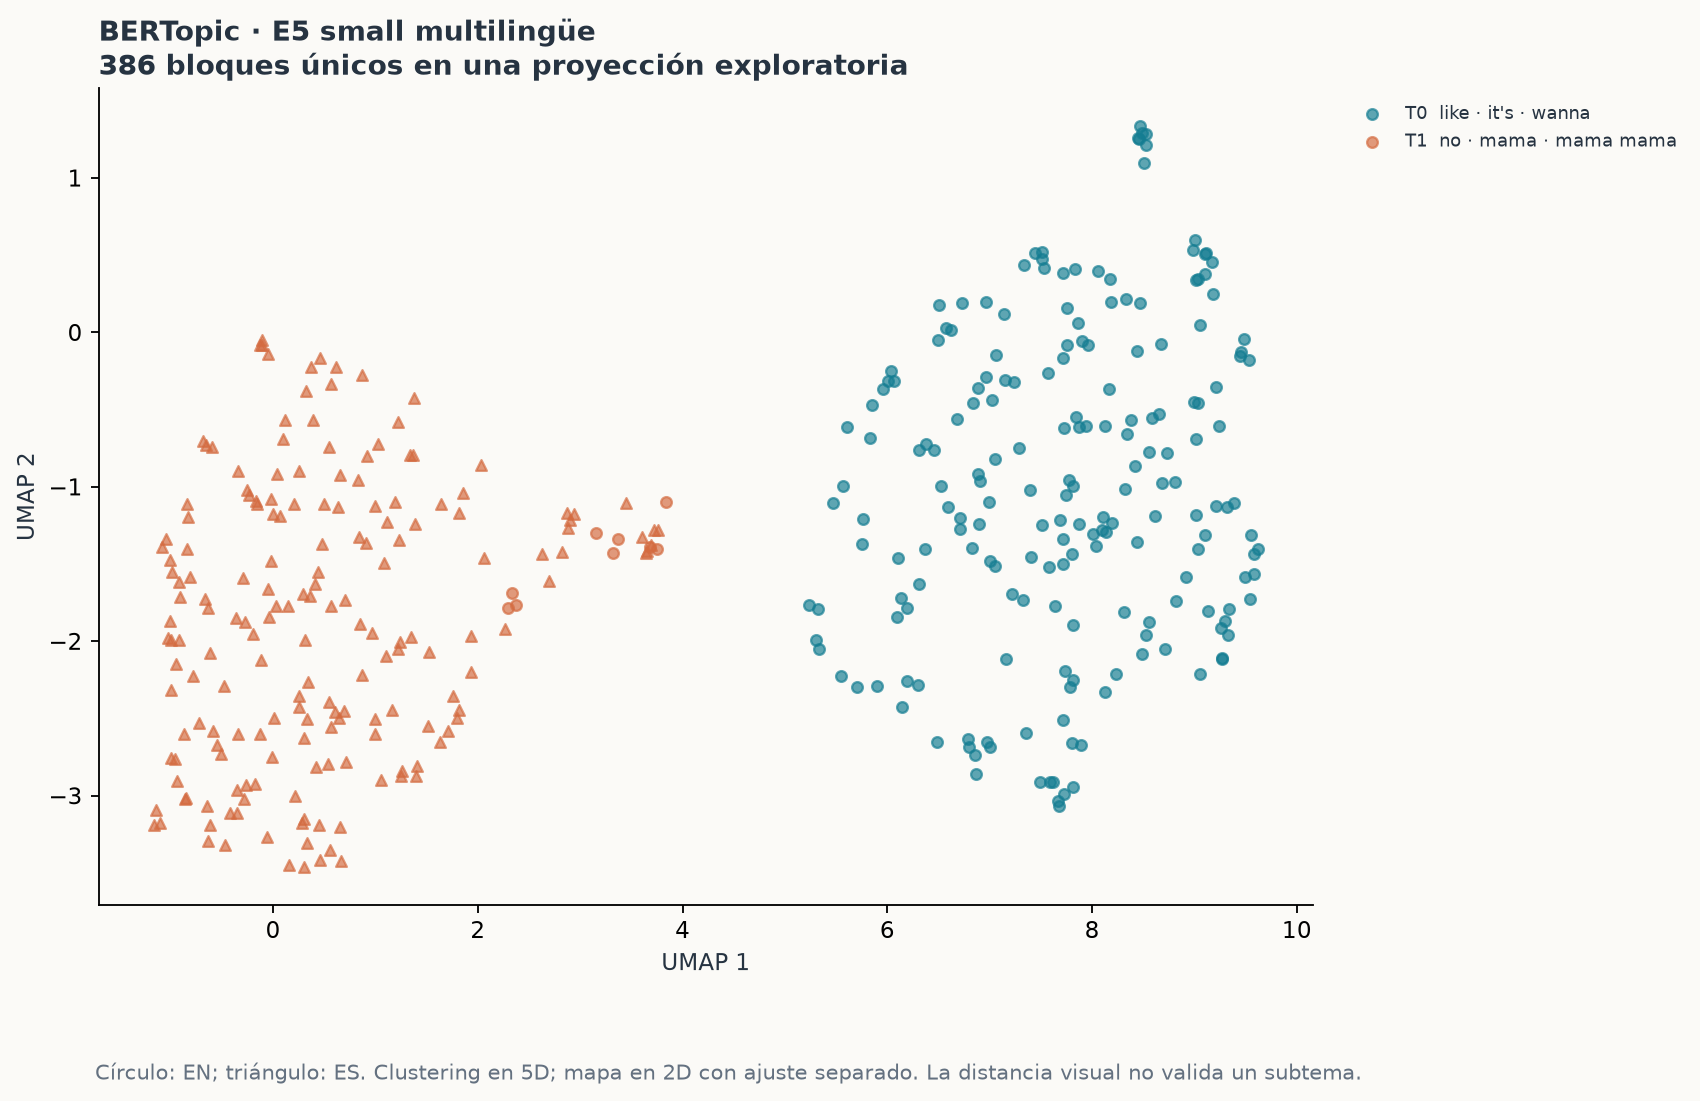

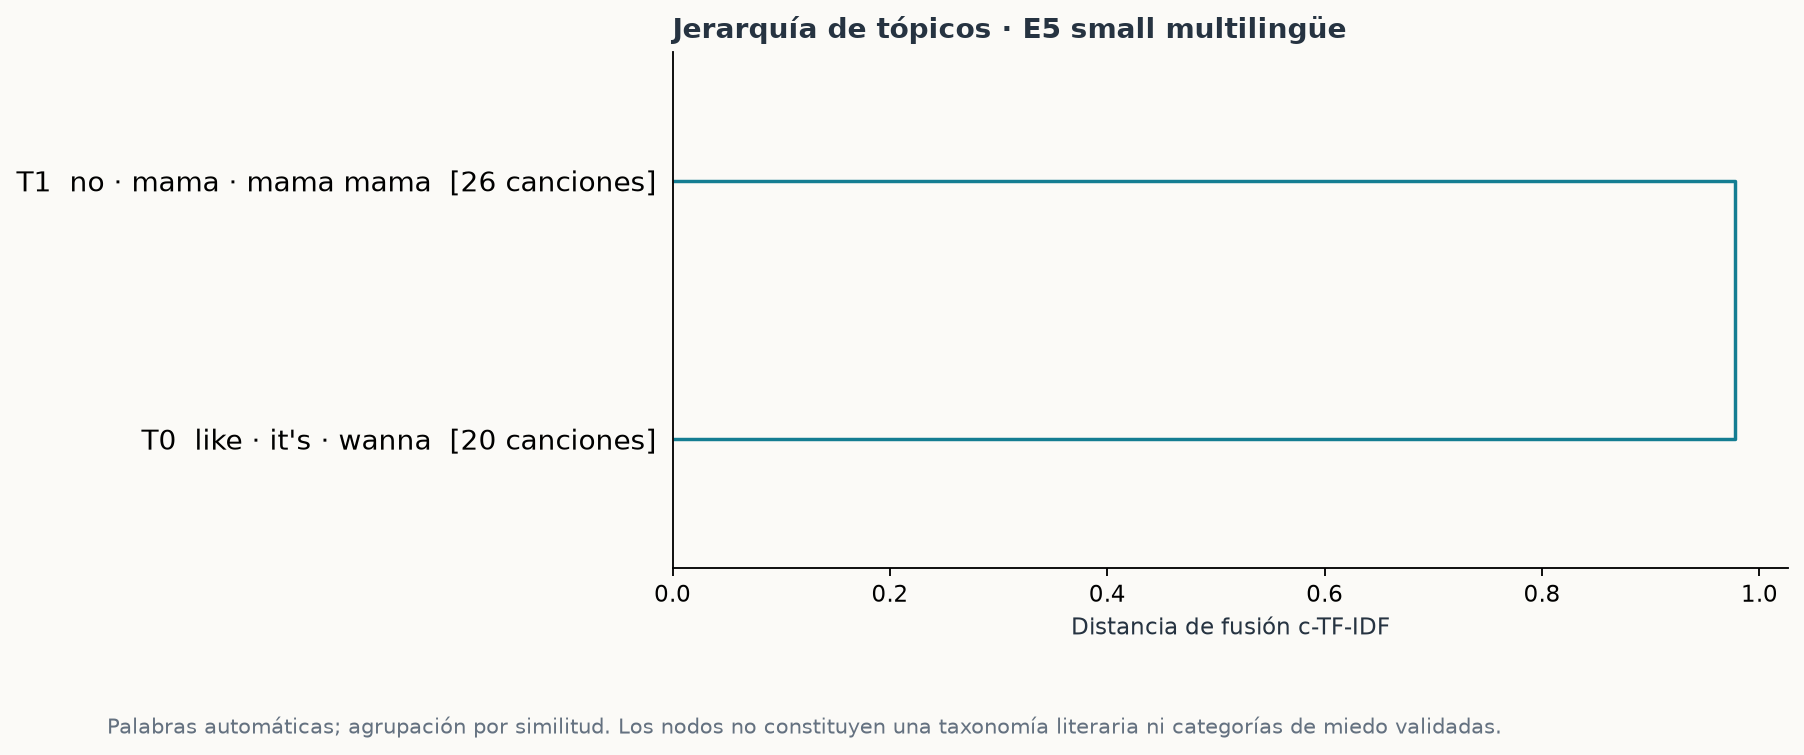

### openai--text-embedding-3-large

,tópico,bloques,canciones,palabras
0,-1,14,6,hi · problem it's · problem · it's hi · agrees...
1,0,173,20,mama mama · mama · no · mal · matador · mu
2,1,55,13,head · belong · belong together · zombie · wis...
3,2,26,4,thriller · thriller night · night · disturbia ...
4,3,24,3,crazy · got · looking crazy · got looking · lo...
5,4,22,1,shit · hope · slim · about · man · stan
6,5,17,2,yet · clear · clear yet · woods · yet clear · ...
7,6,16,12,bum · bum bum · dum bum · dum · bum dum · doo
8,7,12,1,watching · always feel · like somebody's · som...
9,8,10,2,never · off never · we're off · never never · ...


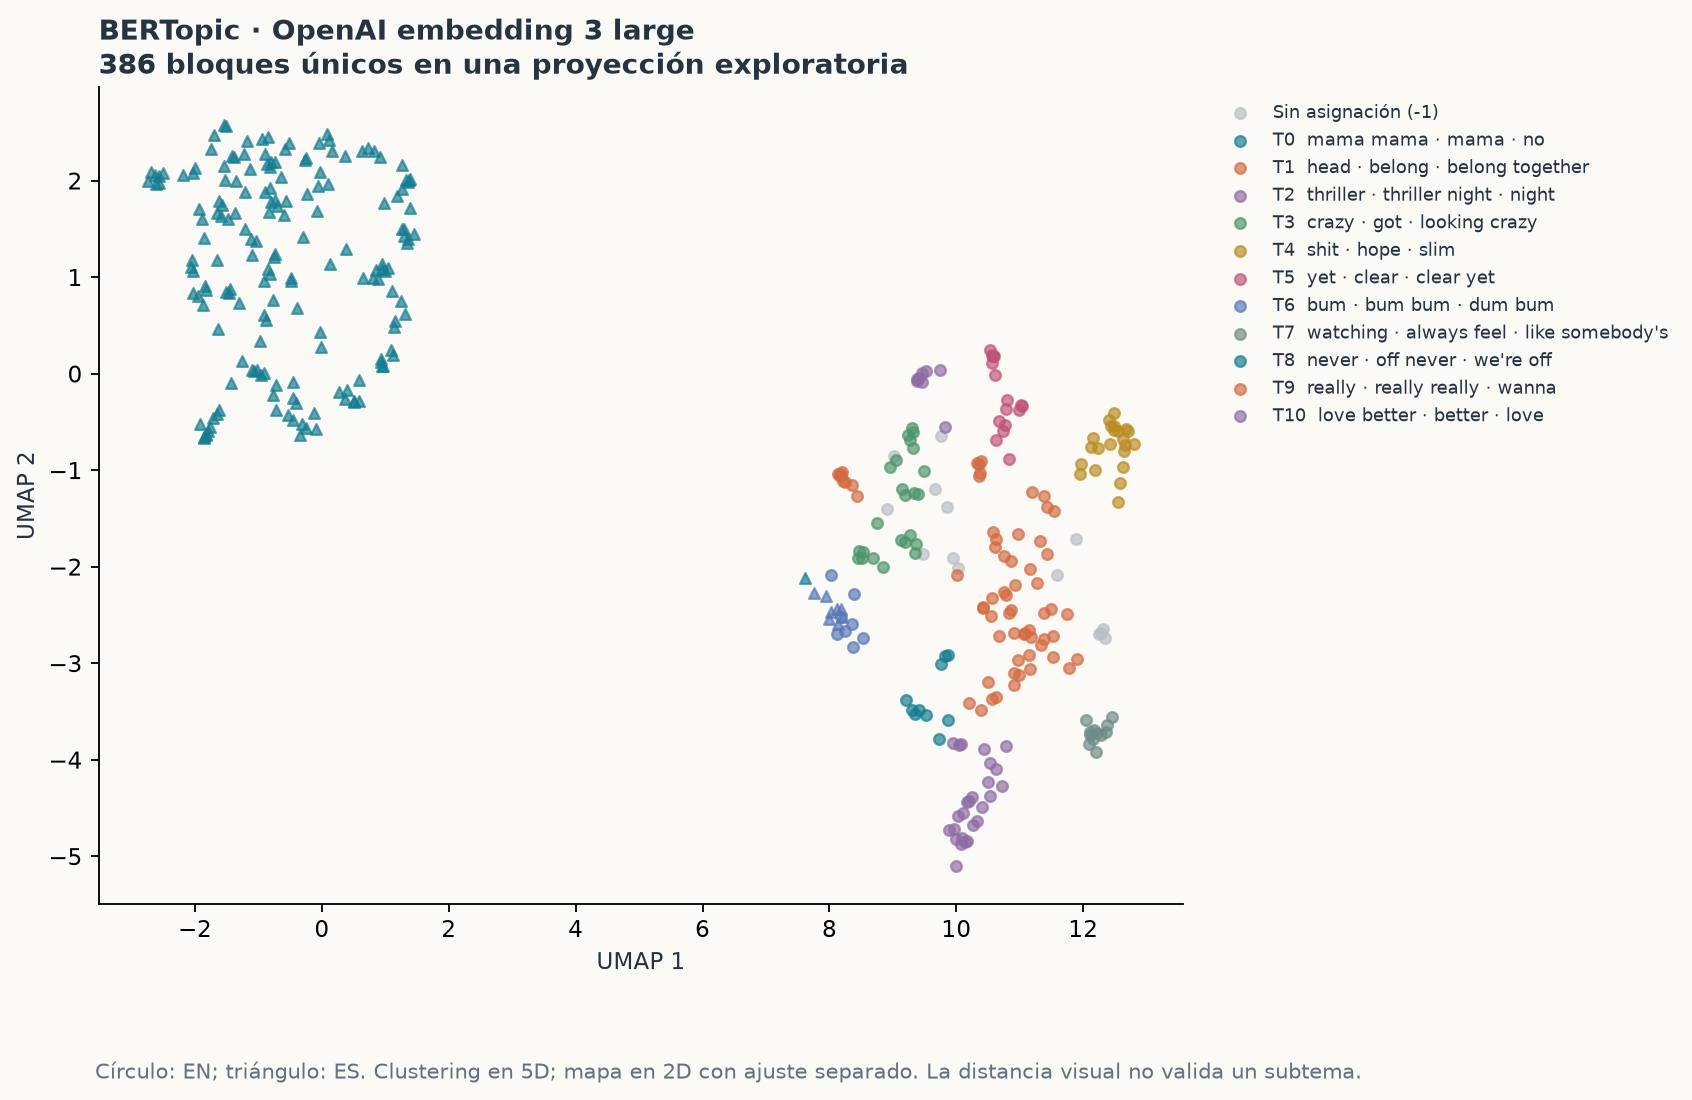

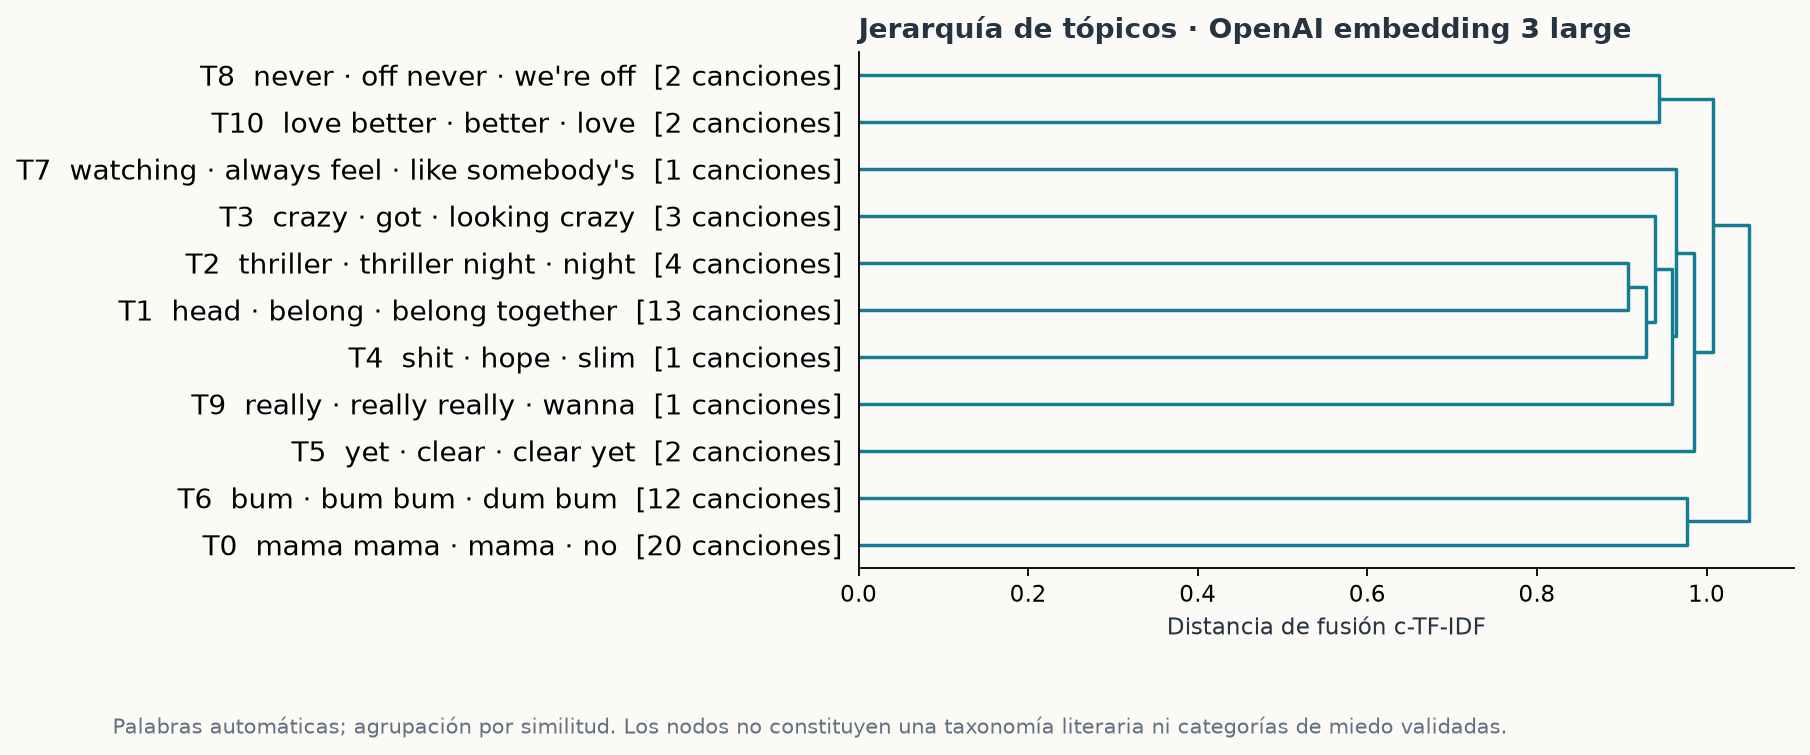

### sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2

,tópico,bloques,canciones,palabras
0,-1,75,29,muevo · go · mad world · ansiedad · world · mario
1,0,31,12,didn't · miedo · shit · verte · no verte · ver...
2,1,26,8,thriller · disturbia · thriller thriller · ton...
3,2,21,3,watching · always · always feel · like somebod...
4,3,21,13,mama mama · mama · bum · bum bum · dum · bum dum
5,4,21,10,never · we're off · off never · never never · ...
6,5,19,5,love better · better · happy · better love · l...
7,6,19,9,luna · ah ah · ah · niño · mujer · hijo
8,7,18,6,really · really really · wanna · voy · hey wan...
9,8,18,11,saber no · duele · pena · piense · olvida · du...


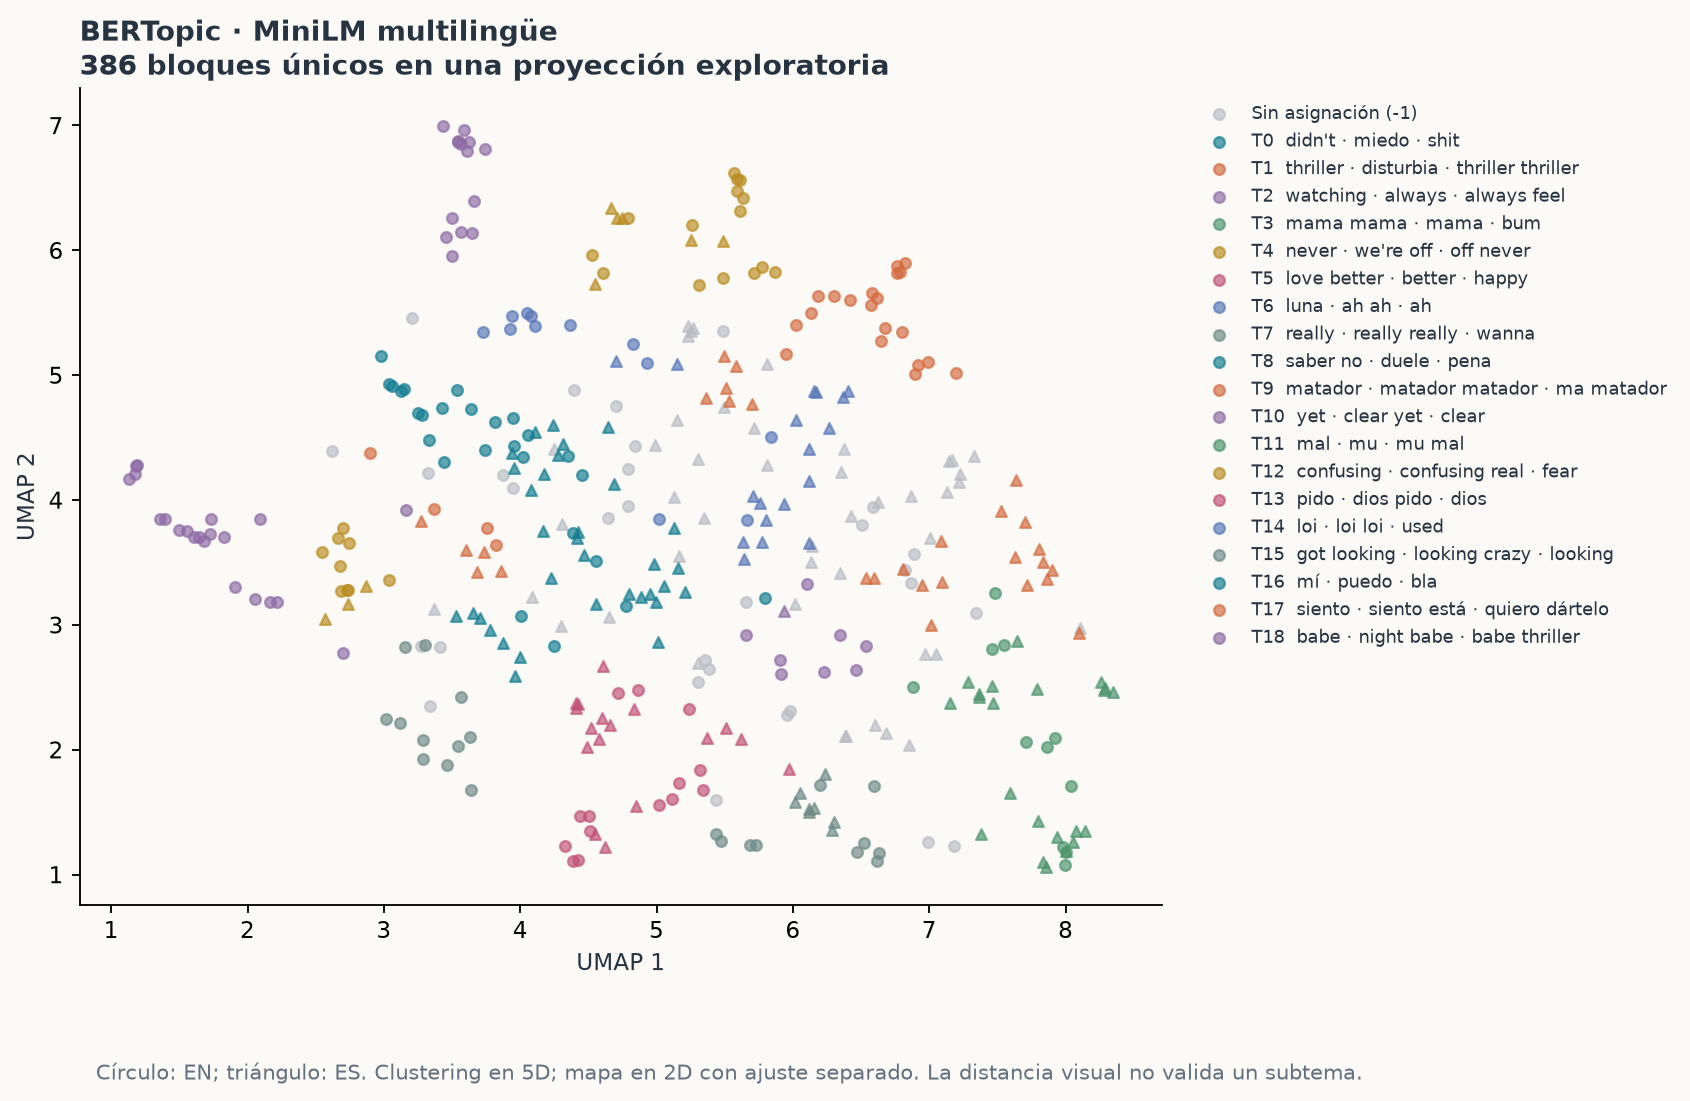

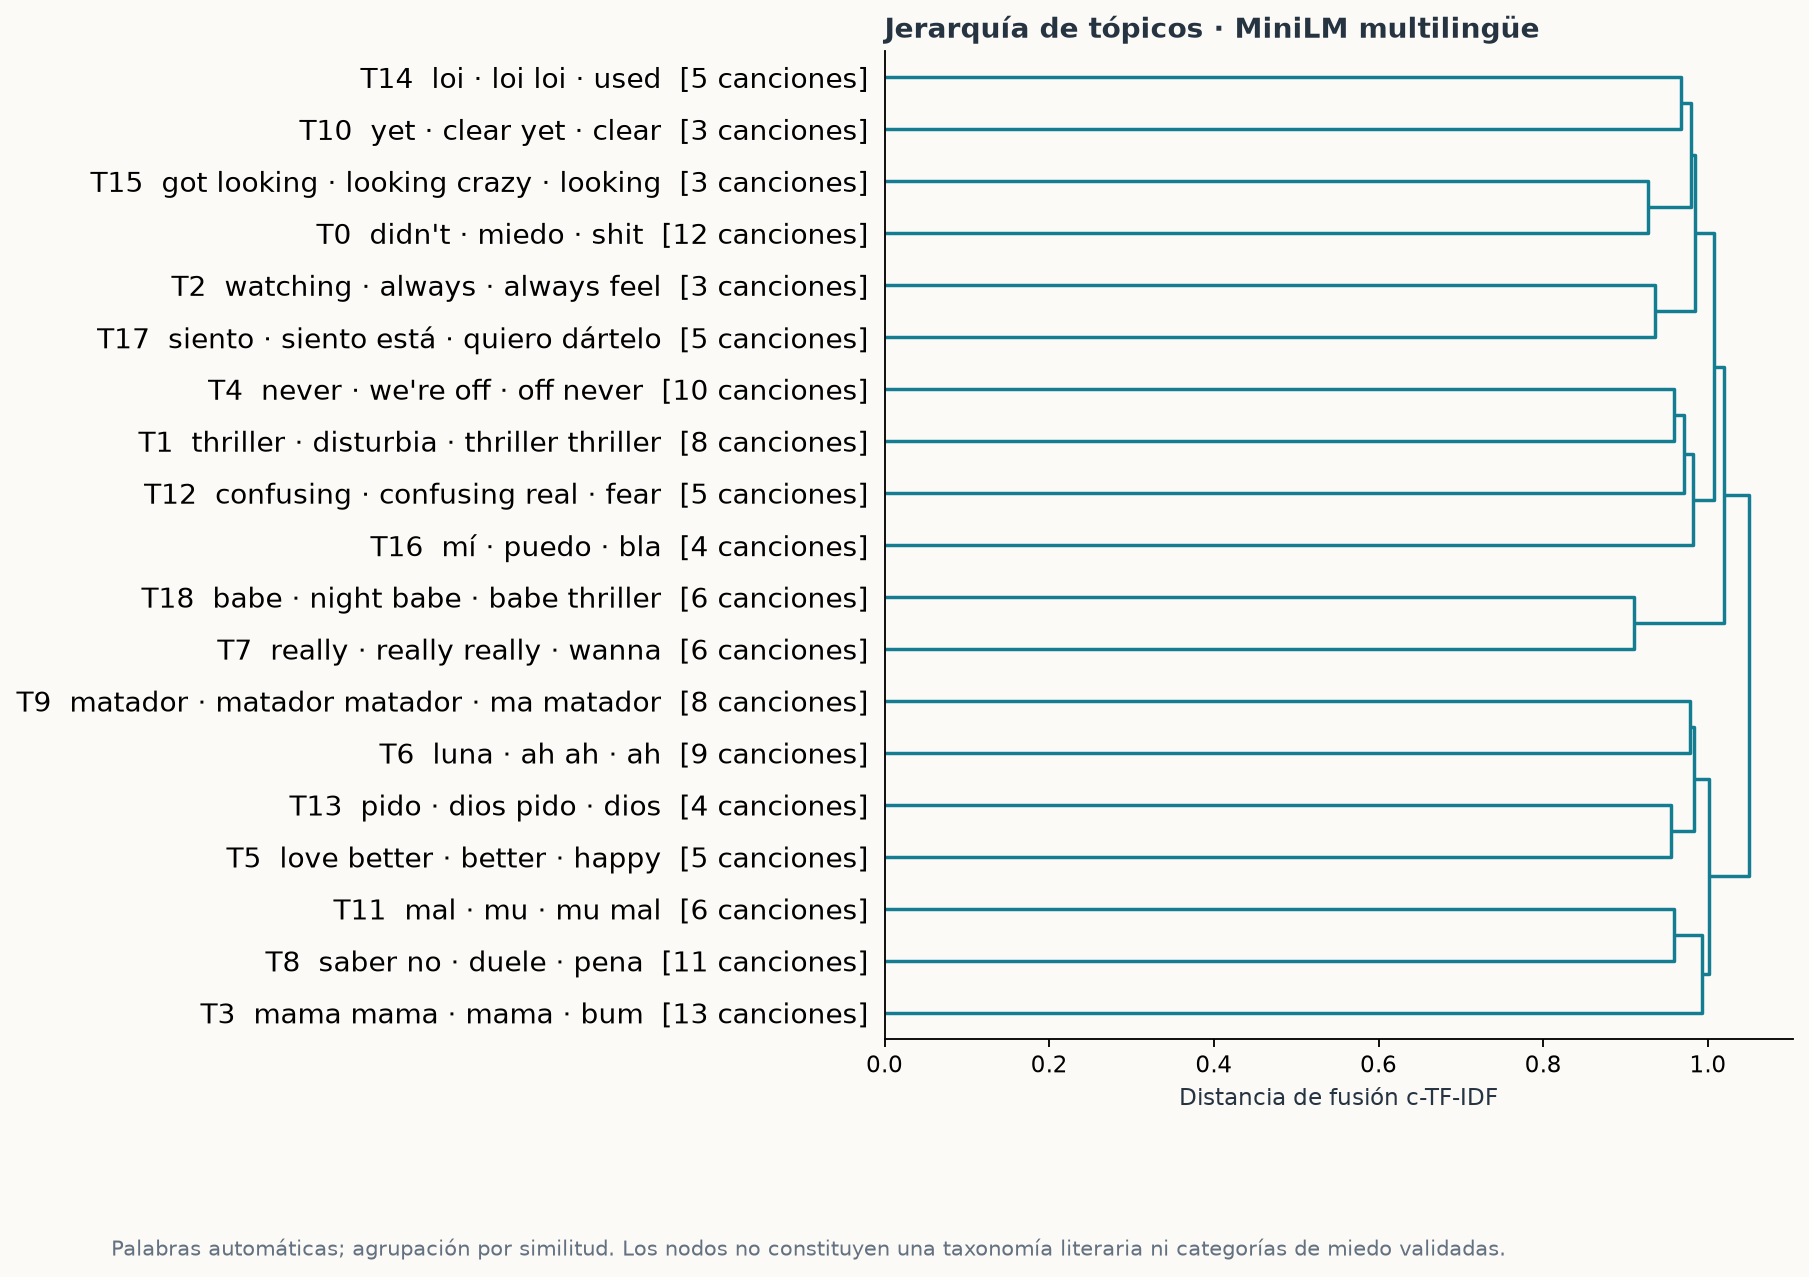

In [7]:
cardsfile = STUDY/'interpretive-cards.json'
if cardsfile.exists():
    cards = read(cardsfile)
    display(Markdown('Fichas propuestas por el asistente: `interpretive-cards.json`, sin validación humana. No constituyen gold ni etiquetas de clusters.'))
    display(pd.DataFrame([{'canción':c['title'],'subtema_propuesto':c['proposed_subtopic']['label'],'límite':c['interpretive_limit']} for c in cards['cards']]))
    display(Image(filename=str(STUDY/'figures/reading-cases.png')))
for directory in modeldirs:
    topics = read(directory/'topics.json')['topics']
    table = pd.DataFrame([{'tópico':t['topic_id'], 'bloques':t['unique_blocks'], 'canciones':t['songs'],
                            'palabras':' · '.join(x['term'] for x in t['terms'][:6])} for t in topics])
    display(Markdown('### '+directory.name))
    display(table)
    display(Image(filename=str(STUDY/f'figures/{directory.name}-map.png')))
    hierarchy = STUDY/f'figures/{directory.name}-hierarchy.png'
    if hierarchy.exists(): display(Image(filename=str(hierarchy)))

## 8. Exigir estabilidad y medir la concentración

La estabilidad entre semillas se mide con adjusted Rand index (ARI), mostrando también qué fracción queda asignada en ambas corridas. El `-1` no se renombra como tópico para mejorar el acuerdo. Un acuerdo alto sobre todo ruido no valida subtemas.

La comparación entre encoders pregunta si conservan una partición semejante sobre los mismos bloques. No compara los números de tópico: T0 de MiniLM y T0 de E5 no nombran el mismo objeto. Las concentraciones por artista y la retirada de un artista muestran cuánto depende una descripción de unos pocos intérpretes. Este control describe composición; no reentrena un clustering alternativo por cada retirada.

[Investigación de 2025 sobre covariables de tópicos](https://aclanthology.org/2025.naacl-long.134/) recuerda que resultados explicativos pueden heredar inestabilidad del modelo de temas. La interpretación histórica necesita sobrevivir a la elección de representación, no únicamente a una figura.

### intfloat--multilingual-e5-small

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,386,1.0,1.0,386,1.0,1.0,1.0,0.0,0.0,2,2,High agreement on a single/noise cluster is no...
1,17,73,386,1.0,1.0,386,1.0,1.0,1.0,0.0,0.0,2,2,High agreement on a single/noise cluster is no...
2,42,73,386,1.0,1.0,386,1.0,1.0,1.0,0.0,0.0,2,2,High agreement on a single/noise cluster is no...


,topic_id,artist_hhi,largest_artist,largest_artist_share,contributing_artists,total_song_normalized_mass,limitation
0,0,0.061319,billie eilish,0.104801,18,19.083816,Artist concentration within this selected corp...
1,1,0.064378,mecano,0.095620,22,20.916184,Artist concentration within this selected corp...


### openai--text-embedding-3-large

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,386,0.946182,0.896373,361,0.935233,0.971119,0.947368,0.036269,0.038860,11,12,High agreement on a single/noise cluster is no...
1,17,73,386,0.942085,0.906736,362,0.937824,0.967595,0.941989,0.036269,0.049223,11,11,High agreement on a single/noise cluster is no...
2,42,73,386,0.942873,0.865285,355,0.919689,0.978205,0.932394,0.038860,0.049223,12,11,High agreement on a single/noise cluster is no...


,topic_id,artist_hhi,largest_artist,largest_artist_share,contributing_artists,total_song_normalized_mass,limitation
5,4,1.000000,eminem feat. dido,1.000000,1,0.956522,Artist concentration within this selected corp...
8,7,1.000000,rockwell,1.000000,1,1.000000,Artist concentration within this selected corp...
10,9,1.000000,spice girls,1.000000,1,0.900000,Artist concentration within this selected corp...
11,10,0.818534,miley cyrus,0.899083,2,0.707792,Artist concentration within this selected corp...
9,8,0.627075,metallica,0.752066,2,0.930769,Artist concentration within this selected corp...
6,5,0.608889,taylor swift,0.733333,2,1.363636,Artist concentration within this selected corp...
3,2,0.413690,michael jackson,0.590526,4,1.693407,Artist concentration within this selected corp...
0,-1,0.246766,taylor swift,0.400802,6,1.782143,Artist concentration within this selected corp...


### sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2

,left_seed,right_seed,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,17,42,386,0.584913,0.766839,288,0.746114,0.791172,0.843750,0.194301,0.196891,19,19,High agreement on a single/noise cluster is no...
1,17,73,386,0.538644,0.769430,303,0.784974,0.750385,0.851485,0.194301,0.121762,19,16,High agreement on a single/noise cluster is no...
2,42,73,386,0.515860,0.730570,297,0.769430,0.797425,0.835017,0.196891,0.121762,19,16,High agreement on a single/noise cluster is no...


,topic_id,artist_hhi,largest_artist,largest_artist_share,contributing_artists,total_song_normalized_mass,limitation
14,13,0.533511,juanes,0.708661,4,1.411111,Artist concentration within this selected corp...
16,15,0.519204,beyoncé feat. jay-z,0.684524,3,0.730435,Artist concentration within this selected corp...
13,12,0.484615,linkin park,0.670290,5,1.491891,Artist concentration within this selected corp...
18,17,0.432958,amaia,0.626947,5,1.329193,Artist concentration within this selected corp...
17,16,0.410845,carla morrison,0.585854,4,1.024145,Artist concentration within this selected corp...
12,11,0.357647,rosalía,0.518655,5,1.583766,Artist concentration within this selected corp...
7,6,0.317995,mecano,0.518129,7,1.930022,Artist concentration within this selected corp...
15,14,0.339725,twenty one pilots,0.512277,5,1.301379,Artist concentration within this selected corp...


,model,diagnostic,nmi_topic_language,documents,interpretation
0,intfloat--multilingual-e5-small,posthoc_language_association,0.863072,386,"Confound diagnostic, not thematic validity."
1,openai--text-embedding-3-large,posthoc_language_association,0.508323,386,"Confound diagnostic, not thematic validity."
2,sentence-transformers--paraphrase-multilingual...,posthoc_language_association,0.112719,386,"Confound diagnostic, not thematic validity."


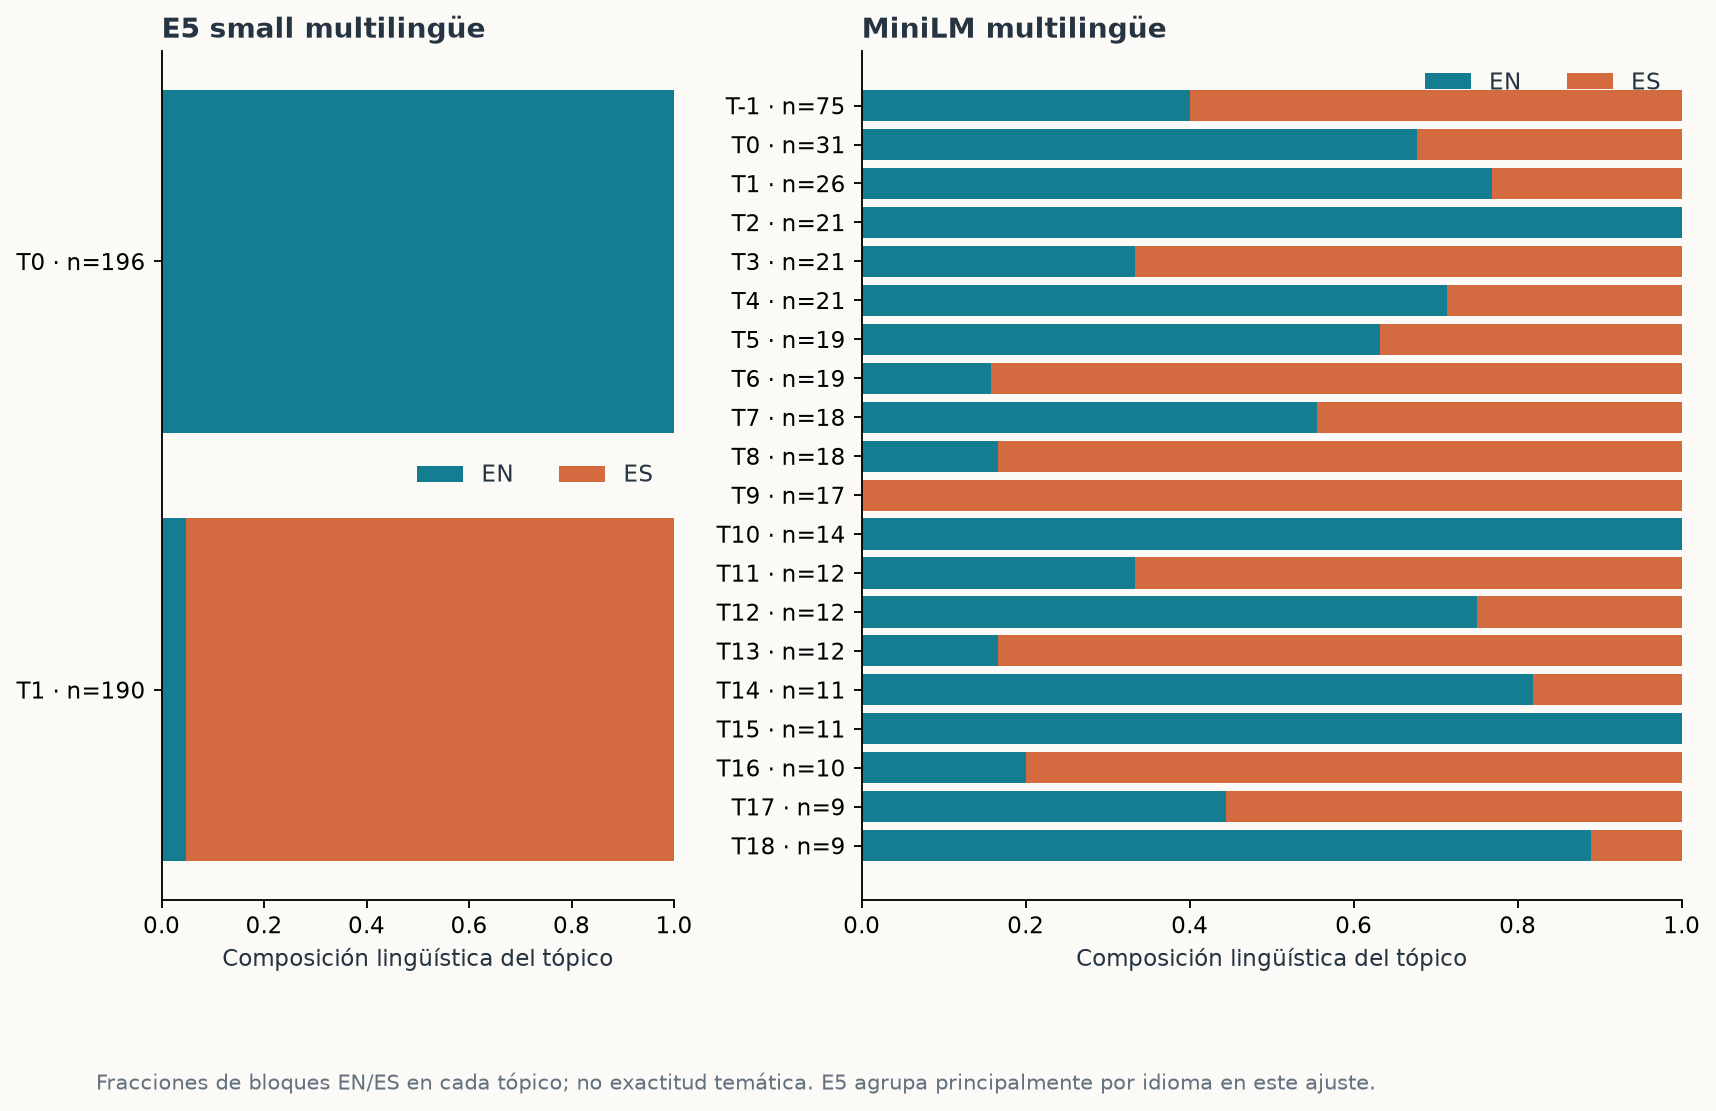

,left_model,right_model,documents,ari_including_noise,label_aligned_fraction_including_noise,both_nonnoise_documents,both_nonnoise_fraction,ari_on_both_nonnoise,label_aligned_fraction_both_nonnoise,left_noise_fraction,right_noise_fraction,left_nonnoise_clusters,right_nonnoise_clusters,limitation
0,intfloat--multilingual-e5-small,openai--text-embedding-3-large,386,0.475189,0.590674,372,0.963731,0.508898,0.612903,0.000000,0.036269,2,11,High agreement on a single/noise cluster is no...
1,intfloat--multilingual-e5-small,sentence-transformers--paraphrase-multilingual...,386,0.032632,0.106218,311,0.805699,0.043237,0.131833,0.000000,0.194301,2,19,High agreement on a single/noise cluster is no...
2,openai--text-embedding-3-large,sentence-transformers--paraphrase-multilingual...,386,0.105848,0.313472,299,0.774611,0.122552,0.397993,0.036269,0.194301,11,19,High agreement on a single/noise cluster is no...


In [8]:
for directory in modeldirs:
    display(Markdown('### '+directory.name))
    display(pd.read_csv(directory/'seed_stability.csv'))
    display(pd.read_csv(directory/'artist_concentration.csv').sort_values('largest_artist_share',ascending=False).head(8))
language_assoc = RESULTS/'topic_language_association.csv'
if language_assoc.exists(): display(pd.read_csv(language_assoc))
display(Image(filename=str(STUDY/'figures/language-confound.png')))
cross = RESULTS/'embedding_model_cluster_agreement.csv'
if cross.exists(): display(pd.read_csv(cross))

## 9. Qué significa una comparación temporal defendible

La distribución por período usa los mismos tópicos globales. No ajustamos cinco modelos independientes y conectamos etiquetas iguales. Tampoco usamos suavizado temporal de c-TF-IDF para insinuar que una palabra apareció en una década donde no estuvo presente.

Cada canción aporta su proporción de bloques en cada tópico; cada idioma aporta la mitad de la media del período. Los controles comparan bloques únicos con todos los bloques, con intervalos pareados. El eje temporal es una cohorte de grabaciones, no una trayectoria de escucha ni del artista: la mayoría aporta una sola canción.

Los cambios visibles pueden deberse a intérpretes, voces, géneros o elecciones del analista. La forma correcta de leerlos es «en estos ocho casos cambia la composición», seguida de evidencia de canciones concretas. No «en los años noventa el miedo se volvió...». La segunda afirmación exigiría un muestreo mucho mayor, una definición de mercado y anotación independiente.

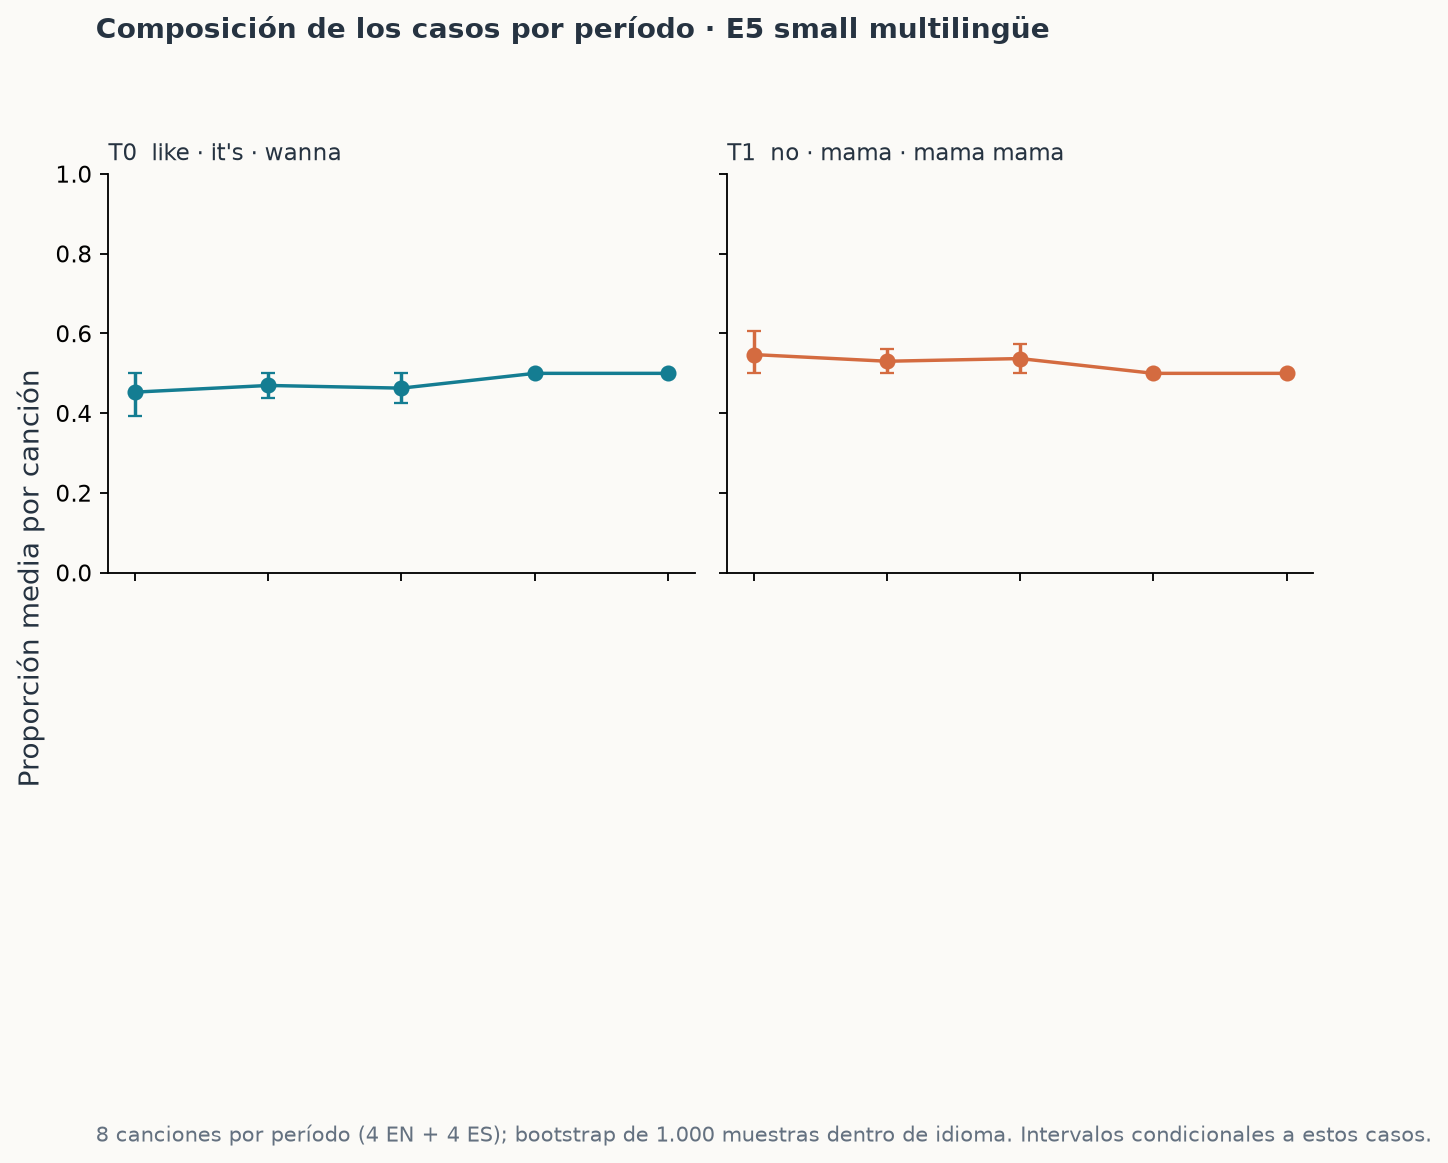

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
12,2000,en,0,0.925824,0.916667,-0.009158,-0.034615,0.007143,True,0.009158
13,2000,en,1,0.074176,0.083333,0.009158,-0.007143,0.034615,True,0.009158
16,2000,balanced_available_languages,0,0.462912,0.458333,-0.004579,-0.017308,0.003571,True,0.004579
17,2000,balanced_available_languages,1,0.537088,0.541667,0.004579,-0.003571,0.017308,True,0.004579
1,1980,en,1,0.094156,0.094231,0.000075,-0.010490,0.010714,True,0.000075


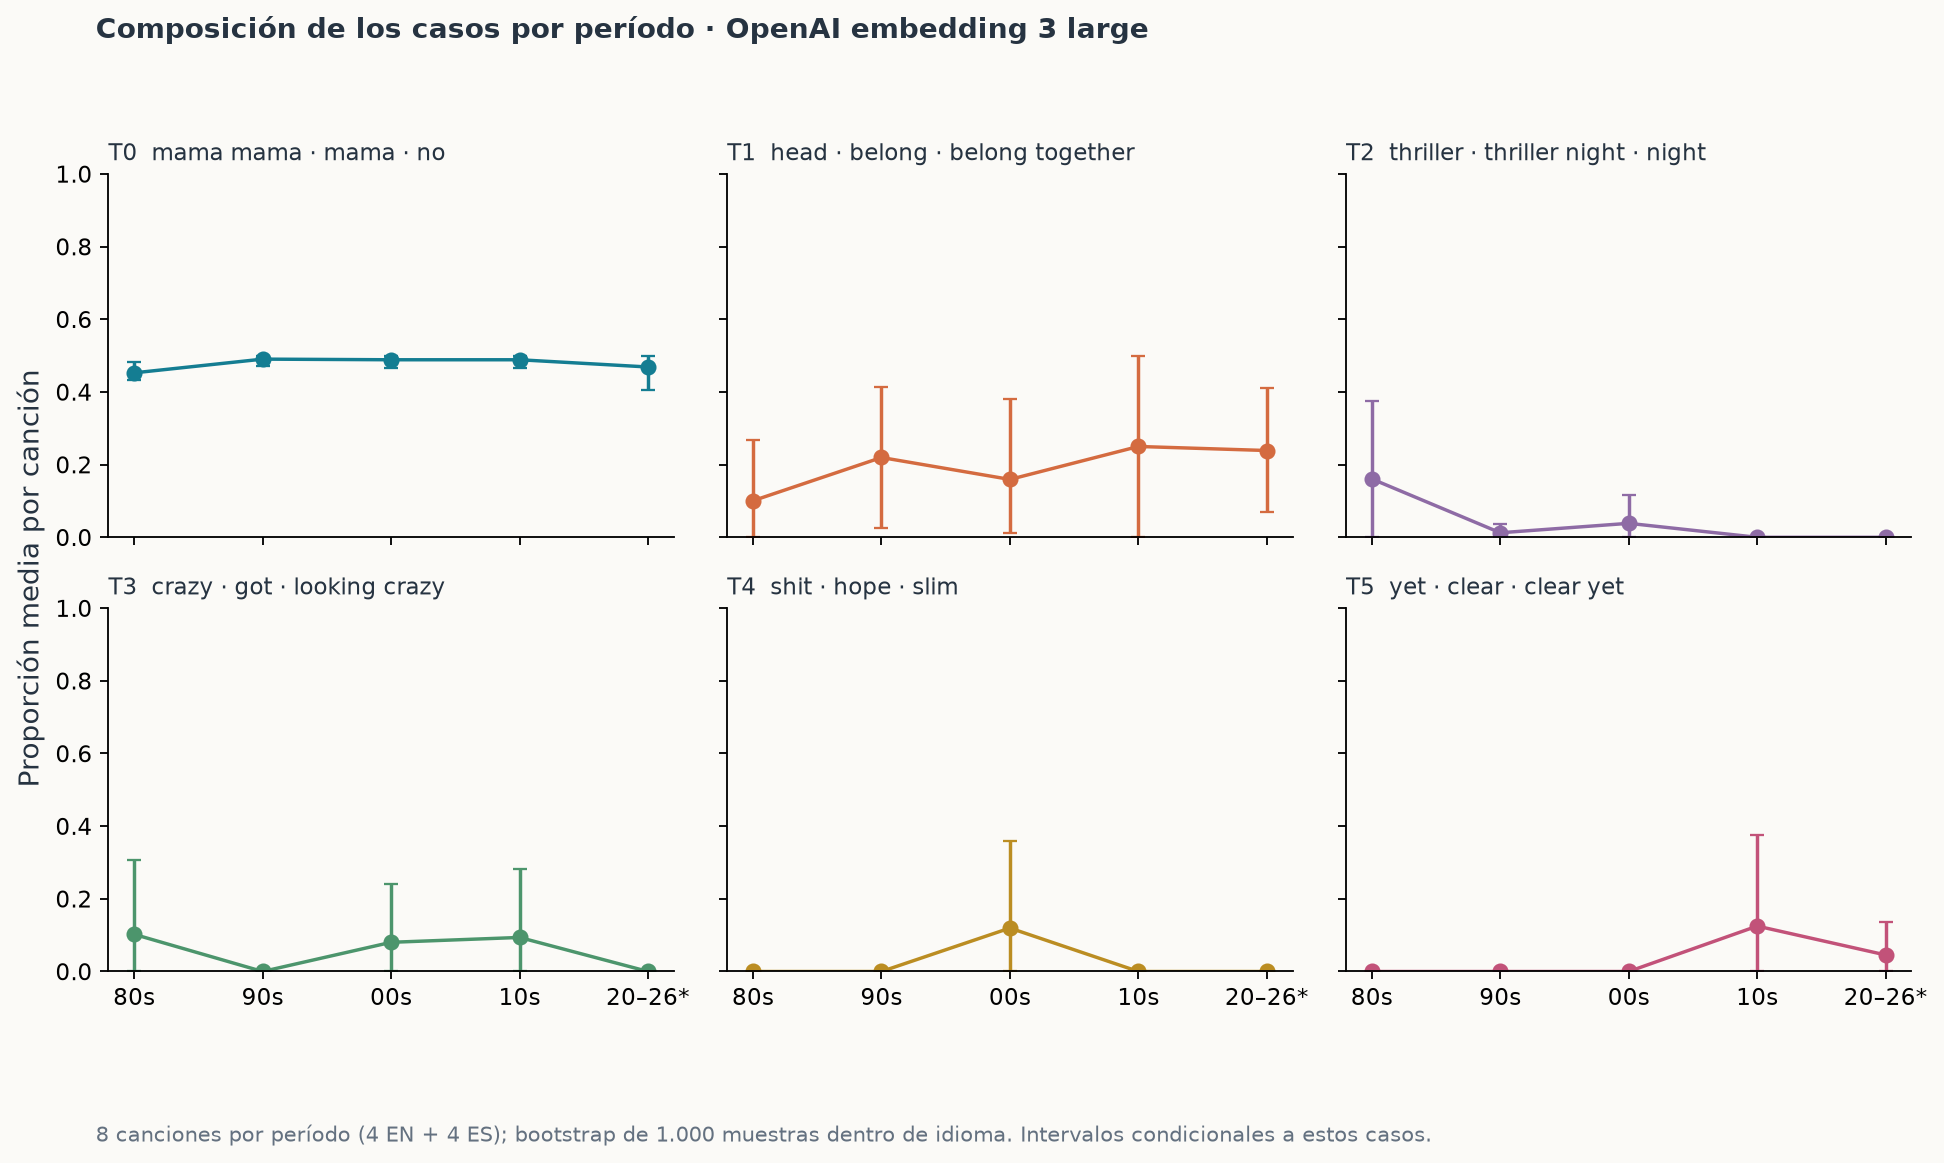

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
77,2000,en,4,0.239130,0.203704,-0.035427,-0.106280,0.000000,True,0.035427
74,2000,en,1,0.318562,0.346296,0.027734,-0.023077,0.106280,True,0.027734
101,2000,balanced_available_languages,4,0.119565,0.101852,-0.017713,-0.053140,0.000000,True,0.017713
19,1980,es,6,0.094742,0.077778,-0.016964,-0.034921,-0.005503,True,0.016964
13,1980,es,0,0.905258,0.922222,0.016964,0.005503,0.034921,True,0.016964


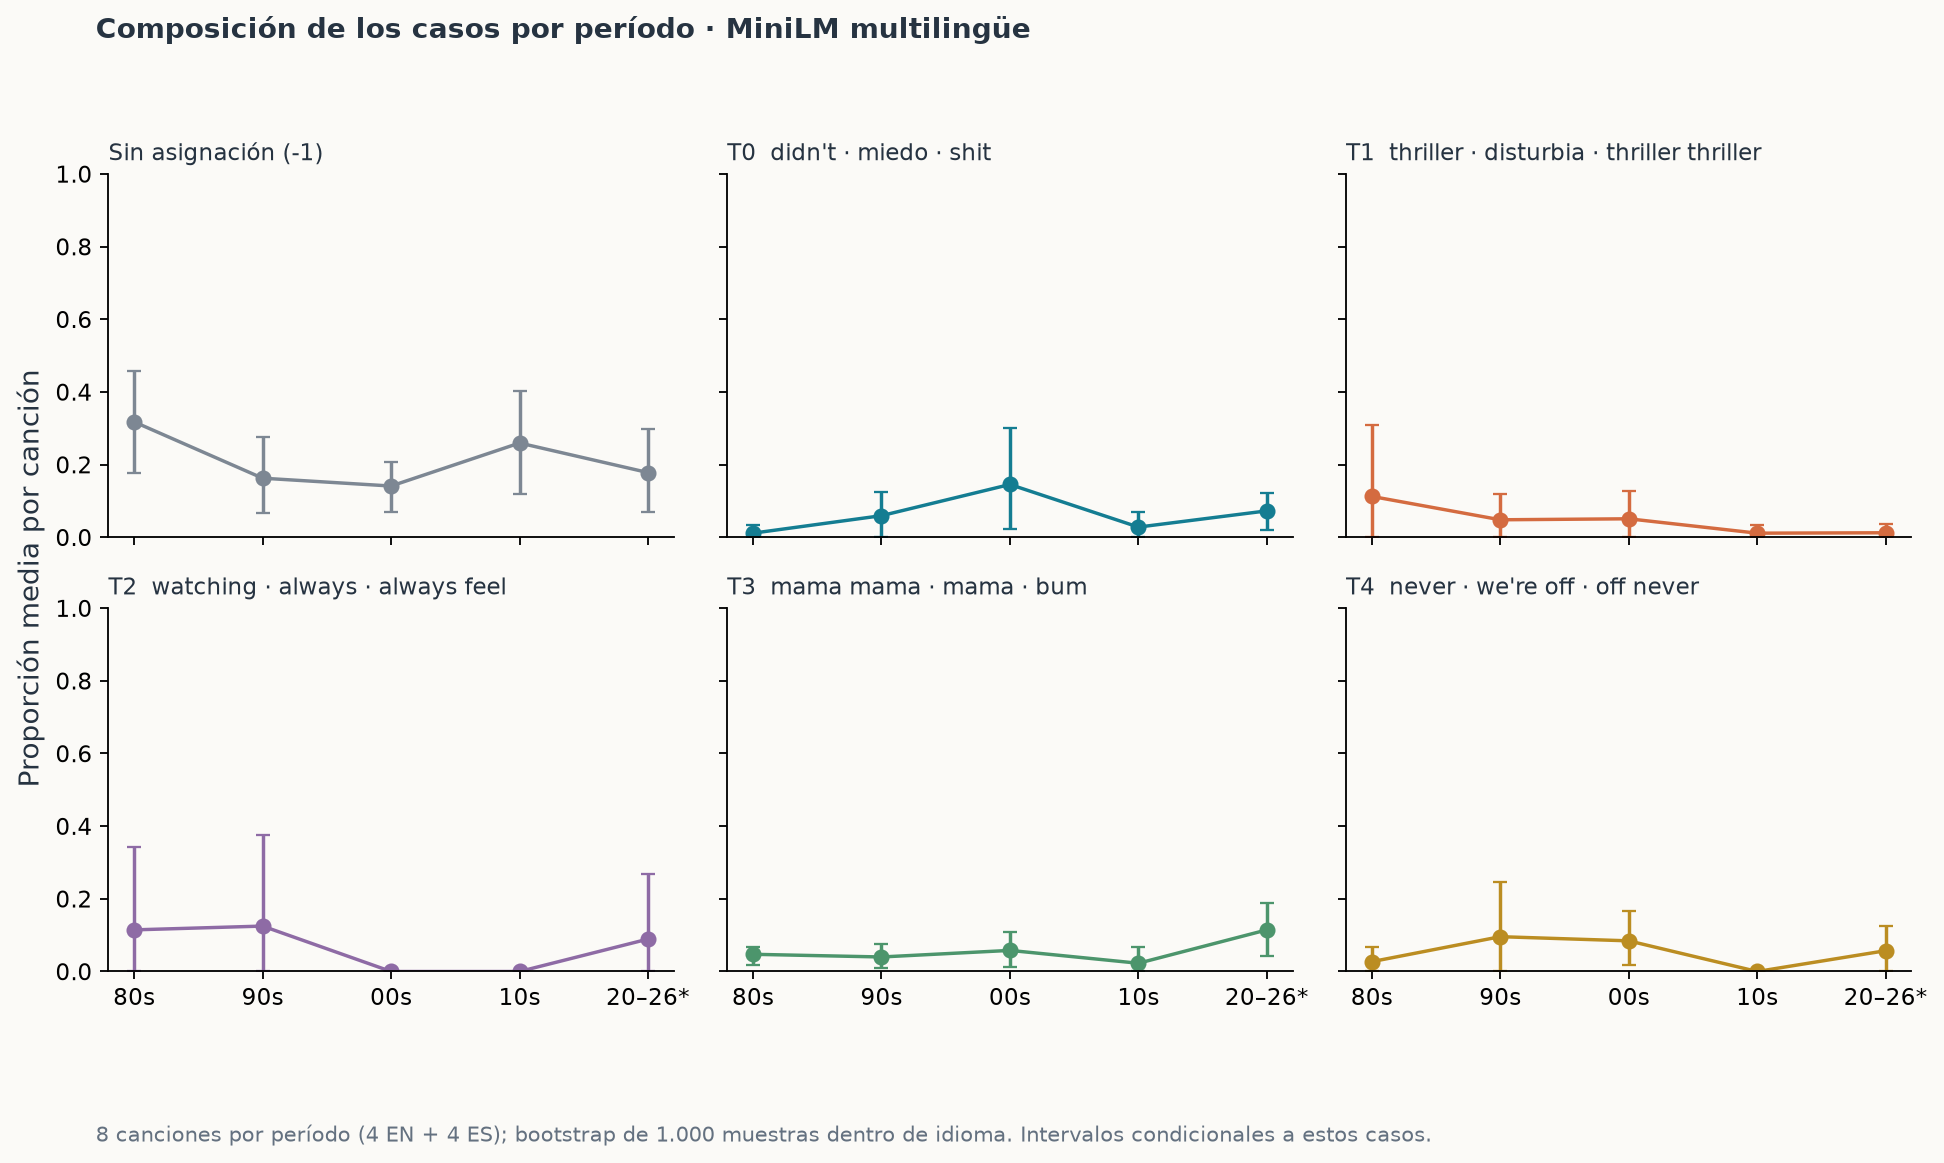

,decade,language,topic_id,unique_share,repeated_share,repeated_minus_unique,paired_ci_low,paired_ci_high,same_fitted_topics,magnitud
140,2000,es,-1,0.186364,0.240833,0.054469,-0.008021,0.171429,True,0.054469
141,2000,es,0,0.138636,0.179845,0.041208,0.000000,0.103571,True,0.041208
160,2000,balanced_available_languages,-1,0.141139,0.181527,0.040388,-0.007802,0.100271,True,0.040388
18,1980,en,17,0.035714,0.075000,0.039286,0.000000,0.117857,True,0.039286
146,2000,es,5,0.075000,0.035714,-0.039286,-0.117857,0.000000,True,0.039286


In [9]:
for directory in modeldirs:
    display(Image(filename=str(STUDY/f'figures/{directory.name}-decades.png')))
    refrains = pd.read_csv(directory/'repeated_refrain_sensitivity.csv')
    display(refrains.assign(magnitud=refrains.repeated_minus_unique.abs()).sort_values('magnitud',ascending=False).head(5))

## 9.1 Tasas, empirical Bayes e incertidumbre del hiperprior

[El ejemplo de Julia Silge](https://juliasilge.com/blog/bayesian-blues/) motiva comparar tasas observadas, estimaciones que comparten información e intervalos posteriores. Aquí adaptamos el denominador: cuatro canciones por idioma y período. La normalización de menciones por población de su tutorial responde una pregunta descriptiva distinta; no trasladamos habitantes a ensayos de canciones.

Contamos presencia binaria de un tópico: una canción tiene al menos un bloque único asignado o no lo tiene. Se conservan ceros y todos los tópicos, incluido ruido. Una canción puede tener varios tópicos; estas tasas no suman uno. No representan prevalencia emocional. La fracción observada se conoce exactamente; el posterior describe una θ hipotética bajo intercambio entre canciones, supuesto no establecido por la selección intencional.

El modelo usa `y_g | θ_g ~ Binomial(4, θ_g)` y `θ_g ~ Beta(α,β)`. El posterior condicional es `Beta(α+y_g, β+4−y_g)`. Empirical Bayes ajusta α y β con likelihood beta-binomial; sus intervalos plug-in condicionan a esa estimación del hiperprior.

El contraste jerárquico integra los hiperparámetros: μ~Beta(1,1), log κ~Normal(log4,1.5), κ en [0.05,200], con cuadratura Gauss–Legendre 64×81. Esos hiperpriors y la truncación son supuestos. Comparamos también Jeffreys, uniforme, pooling por idioma, retirada de una celda, perfiles de κ y resolución numérica.

La unidad canción evita convertir bloques dependientes en ensayos independientes, pero no elimina dependencia de artistas, sesgo de selección ni incertidumbre del clustering. El pooling entre EN/ES puede ser injustificable en una representación dominada por idioma. La comparación muestra cuánto cambia una conclusión al cambiar estos supuestos.

{'status': 'complete',
 'cell_topic_rows': 340,
 'posterior_rows': 2040,
 'fitted_hyperpriors': 102,
 'pooled_eb_boundary_fits': 22,
 'pooled_eb_fits': 34,
 'eb_converged_fits': 100,
 'eb_nonconverged_fits': 2,
 'pooled_eb_profiles_touching_bound': 32,
 'maximum_selected_grid_resolution_difference': 9.132417044810381e-13,
 'maximum_leave_cell_out_plugin_mean_shift': 0.25292545067804284,
 'mean_interval_width_by_method': {'EB_plugin': 0.17931916316610155,
  'hierarchical_grid': 0.3918236421822459,
  'Jeffreys': 0.5501274278375858,
  'uniform': 0.5807553505834997},
 'interpretation': 'Conditional sensitivity of selected-song topic presence. No historical population change or validated fear prevalence is established.'}

,method,prior_context,songs,successes,raw_rate,posterior_mean,credible_low,credible_high,identifiability
784,Jeffreys,fixed,4,2,0.5,0.500000,0.122754,0.877246,fixed_prior_not_fitted
794,uniform,fixed,4,2,0.5,0.500000,0.146633,0.853367,fixed_prior_not_fitted
808,EB_plugin,pooled_languages,4,2,0.5,0.141666,0.077991,0.220384,weak_or_boundary
809,hierarchical_grid,pooled_languages,4,2,0.5,0.279335,0.061997,0.667738,weak_or_boundary
824,EB_plugin,language_en,4,2,0.5,0.267847,0.068845,0.540497,weak_or_boundary
825,hierarchical_grid,language_en,4,2,0.5,0.334611,0.070152,0.747615,weak_or_boundary


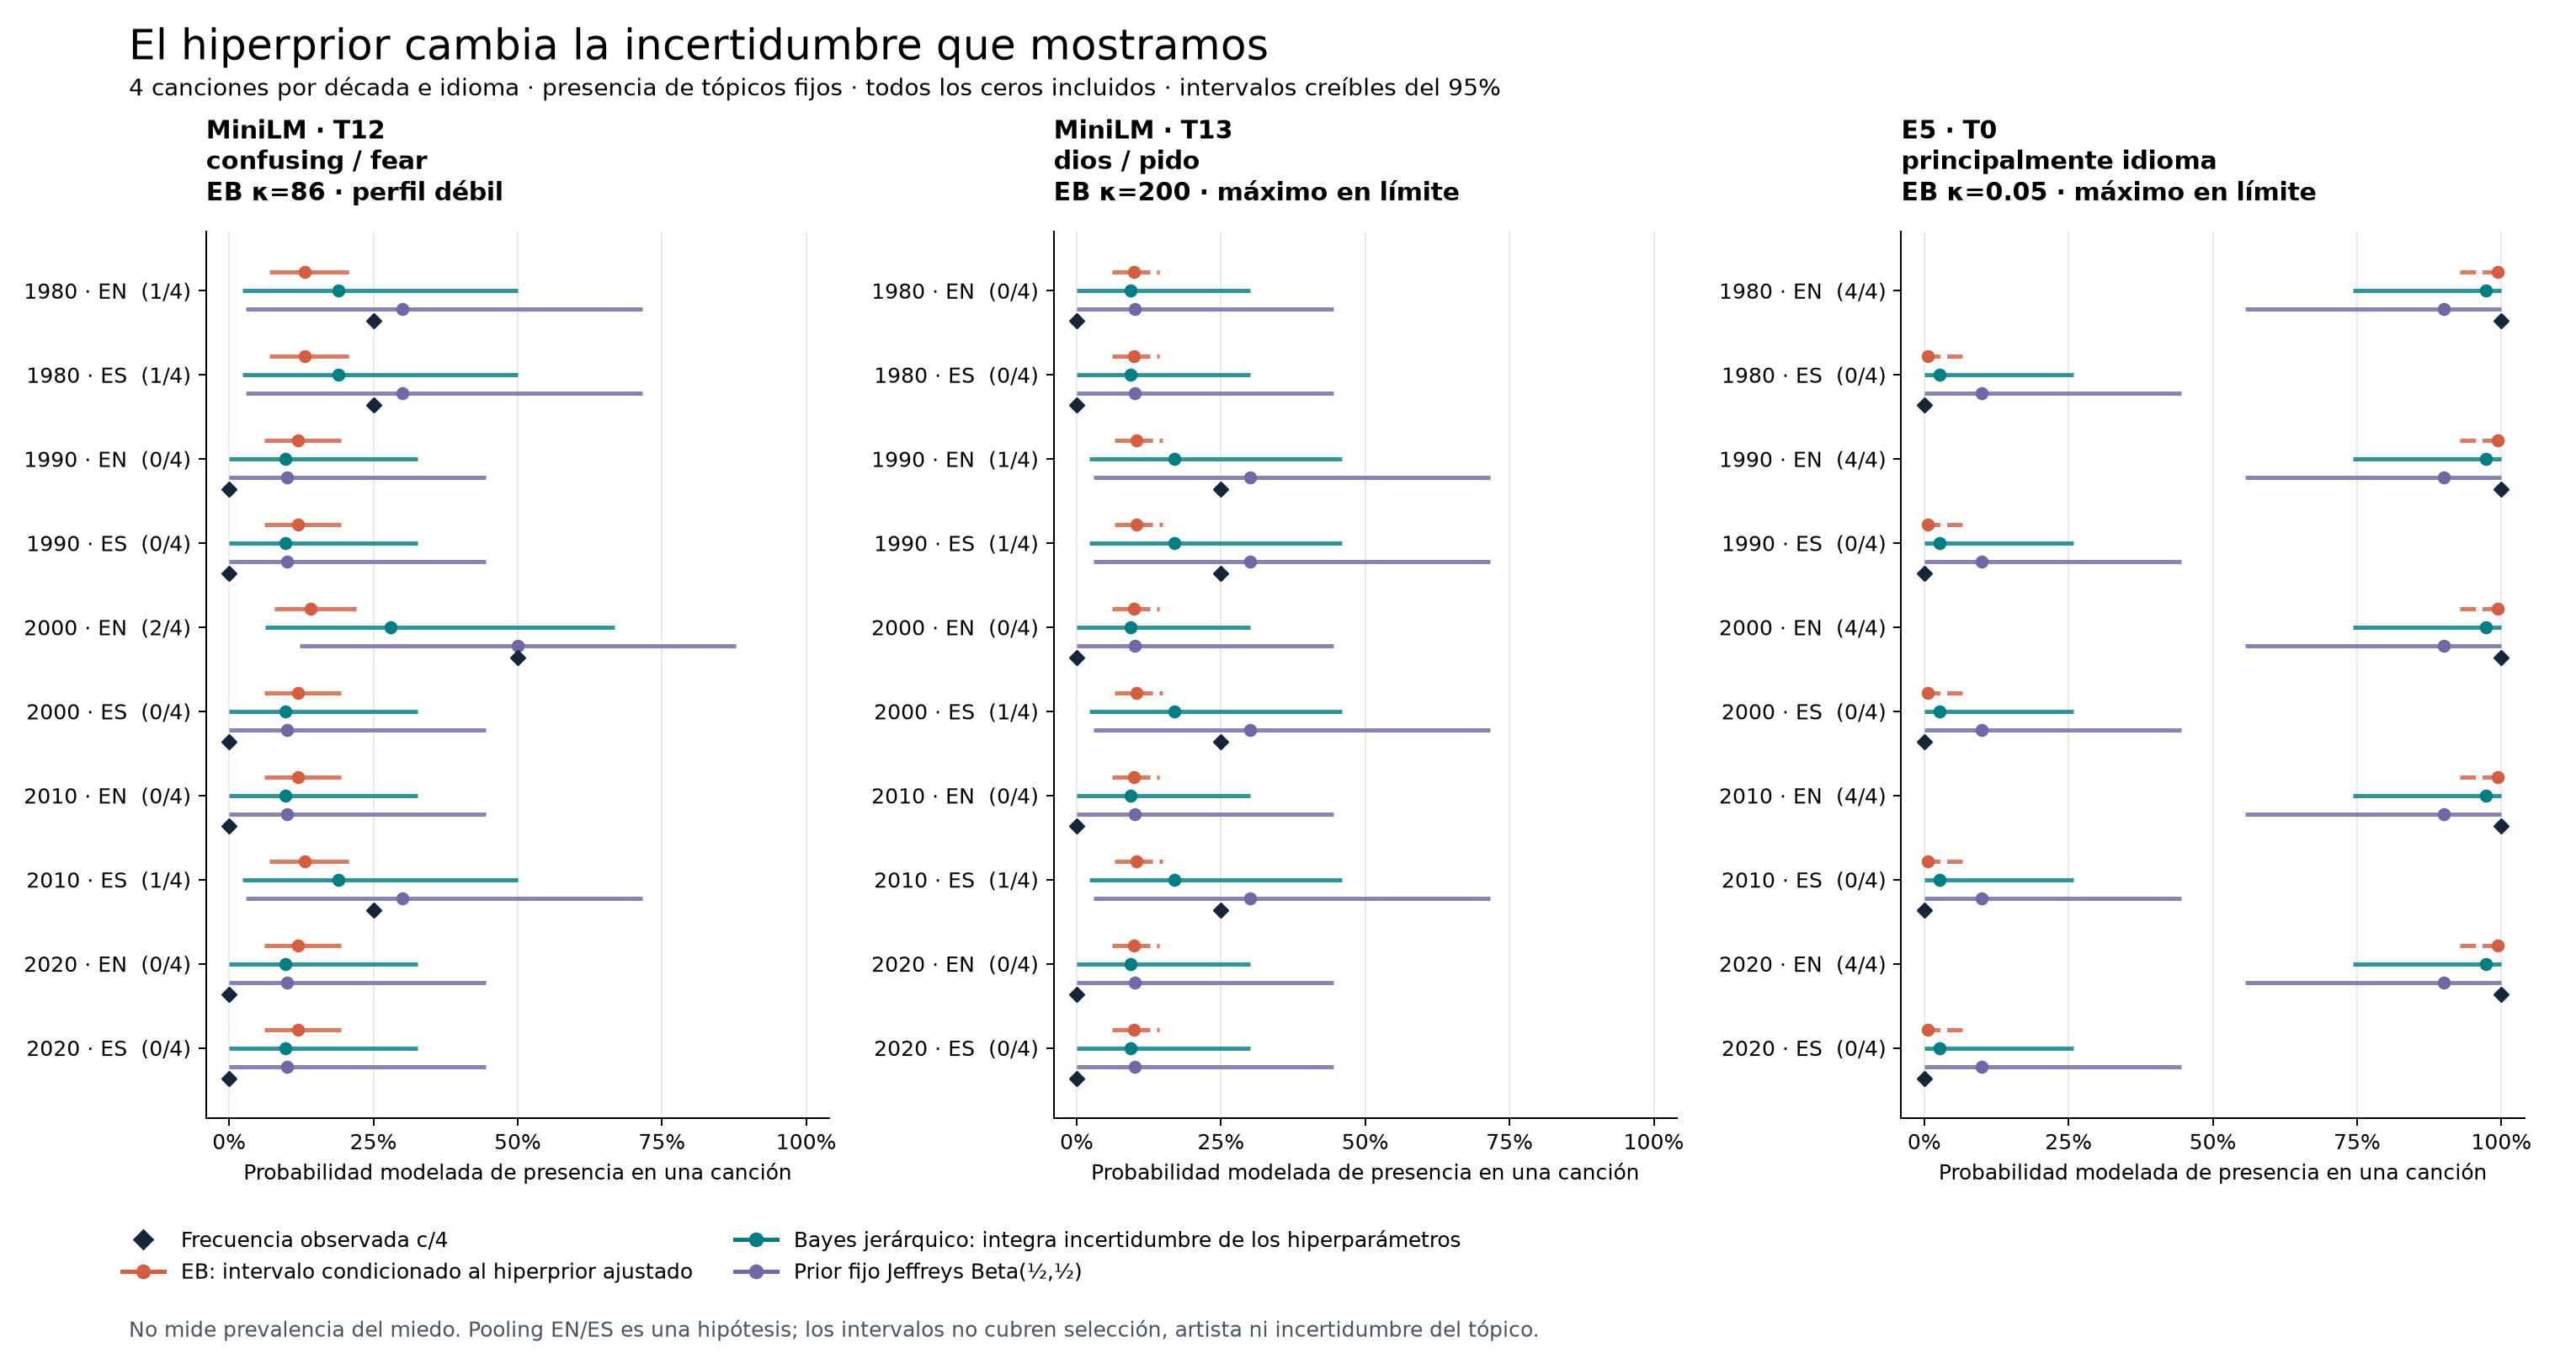

,model,topic_id,prior_context,successes,songs,main_mu_nodes,main_kappa_nodes,comparison_mu_nodes,comparison_kappa_nodes,mean_absolute_difference,low_absolute_difference,high_absolute_difference
0,sentence-transformers/paraphrase-multilingual-...,12,pooled_languages,0,4,64,81,96,121,1.387779e-16,6.396793e-17,2.553513e-15
1,sentence-transformers/paraphrase-multilingual-...,12,pooled_languages,1,4,64,81,96,121,2.220446e-16,3.122502e-17,2.553513e-15
2,sentence-transformers/paraphrase-multilingual-...,12,pooled_languages,2,4,64,81,96,121,2.775558e-16,0.000000e+00,3.441691e-15
3,sentence-transformers/paraphrase-multilingual-...,12,language_en,0,4,64,81,96,121,4.163336e-17,8.965758e-17,1.054712e-15
4,sentence-transformers/paraphrase-multilingual-...,12,language_en,1,4,64,81,96,121,5.551115e-17,1.040834e-17,1.110223e-15
5,sentence-transformers/paraphrase-multilingual-...,12,language_en,2,4,64,81,96,121,1.110223e-16,2.775558e-17,0.000000e+00
6,sentence-transformers/paraphrase-multilingual-...,12,language_es,0,4,64,81,96,121,6.938894e-17,1.436737e-14,3.330669e-16
7,sentence-transformers/paraphrase-multilingual-...,12,language_es,1,4,64,81,96,121,5.551115e-17,4.857226e-17,8.881784e-16
8,sentence-transformers/paraphrase-multilingual-...,13,pooled_languages,0,4,64,81,96,121,9.714451e-17,3.421186e-15,1.720846e-15
9,sentence-transformers/paraphrase-multilingual-...,13,pooled_languages,1,4,64,81,96,121,1.942890e-16,2.081668e-17,1.998401e-15


In [10]:
bayesdir = RESULTS/'bayes'
posterior = pd.read_csv(bayesdir/'posterior_rates.csv')
display(read(bayesdir/'summary.json'))
example = posterior[(posterior.model=='sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2') &
                    (posterior.topic_id==12) & (posterior.decade==2000) & (posterior.language=='en')]
display(example[['method','prior_context','songs','successes','raw_rate','posterior_mean','credible_low','credible_high','identifiability']])
display(Image(filename=str(bayesdir/'beta_binomial_presence.png')))
display(pd.read_csv(bayesdir/'grid_resolution.csv'))

**Crítica del resultado.** En T12 de MiniLM, inglés/2000s, la observación 2/4 da una tasa 0,50. EB la reduce a 0,142 con banda 0,078–0,220; el modelo jerárquico da 0,279 con banda 0,062–0,668; Jeffreys mantiene 0,50 con banda 0,123–0,877. El contraste no se explica únicamente por añadir incertidumbre: el modelo jerárquico introduce hiperpriors explícitos. El intervalo plug-in estrecho no merece más confianza por ser estrecho.

Los ajustes que alcanzan límites o no convergen permanecen señalados. Las bandas posteriores no cubren errores de asignación temática ni selección histórica. Una tasa extrema en cuatro canciones sigue siendo evidencia escasa.

## 10. Del tópico al arco hay una relación que demostrar

Las [seis formas afectivas de Reagan y colaboradores](https://link.springer.com/article/10.1140/epjds/s13688-016-0093-1) se estudiaron en libros extensos. [EmotionArcs 2024](https://aclanthology.org/2024.latechclfl-1.7/) estudia perfiles emocionales en novelas. Trasladar esa evidencia a unas pocas estrofas cambia dominio, escala y unidad. No validamos seis arcos musicales por dibujar seis curvas.

La investigación reciente amplía las preguntas de lectura: [Social Story Frames, ACL 2026](https://aclanthology.org/2026.acl-long.1934/) separa inferencias sobre intención, recepción y contexto, con validación humana sobre historias sociales. Nos sirve para diseñar preguntas y anotaciones; no proporciona un clasificador validado de letras.

Aquí calculamos cuatro similitudes a prototipos bilingües originales: miedo, amenaza, evitación y afrontamiento. La diferencia `afrontamiento − (miedo + amenaza) / 2` es un contraste geométrico. Su pendiente no es intensidad emocional. Las curvas se interpolan solo para comparar posiciones relativas; el audio y su duración no están en el eje.

Una prueba de 1.000 permutaciones intercambia el orden de los bloques manteniendo textos y prototipos. Los valores p se ajustan con Benjamini–Hochberg dentro de cada variante. Una diferencia frente al orden aleatorio informa sobre esa representación concreta. No prueba una trama, una causalidad ni la intención del compositor.

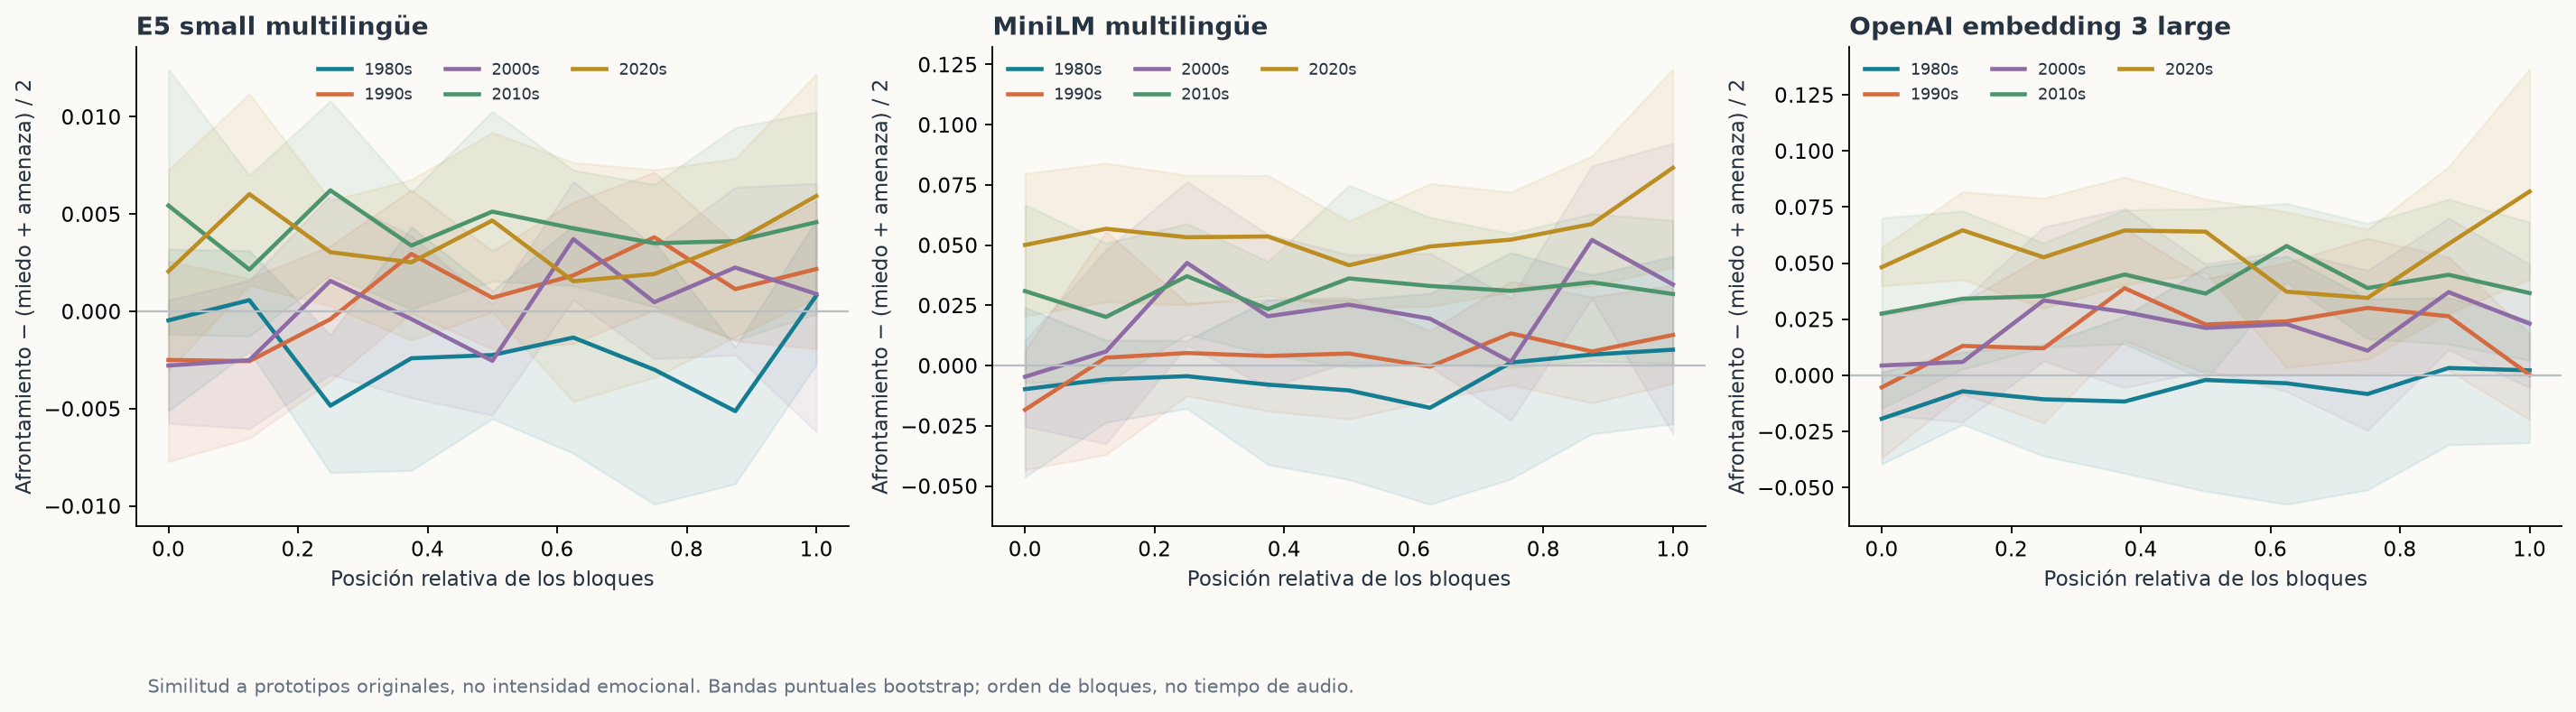

### intfloat--multilingual-e5-small

,variant,group,songs,languages_present,mean_order_slope,shuffled_mean,shuffled_ci_low,shuffled_ci_high,permutation_p_two_sided,weighting,inference,permutation_q_bh_within_variant
0,unique_first_occurrence,all_selected_songs,40,2,0.001855,-0.000017,-0.002163,0.002186,0.097902,equal_language_then_equal_song,Tests section order against exchangeability co...,0.195804
1,unique_first_occurrence,1980,8,2,-0.000681,-0.000082,-0.005314,0.005145,0.810190,equal_language_then_equal_song,Tests section order against exchangeability co...,0.884116
2,unique_first_occurrence,1990,8,2,0.004850,-0.000065,-0.005010,0.004580,0.047952,equal_language_then_equal_song,Tests section order against exchangeability co...,0.170829
3,unique_first_occurrence,2000,8,2,0.004667,0.000066,-0.004618,0.004920,0.056943,equal_language_then_equal_song,Tests section order against exchangeability co...,0.170829
4,unique_first_occurrence,2010,8,2,-0.000328,-0.000014,-0.004140,0.004000,0.884116,equal_language_then_equal_song,Tests section order against exchangeability co...,0.884116
5,unique_first_occurrence,2020,8,2,0.000766,0.000012,-0.005765,0.005952,0.817183,equal_language_then_equal_song,Tests section order against exchangeability co...,0.884116
6,all_blocks_with_repeats,all_selected_songs,40,2,0.002137,0.000031,-0.002244,0.002026,0.051948,equal_language_then_equal_song,Tests section order against exchangeability co...,0.103896
7,all_blocks_with_repeats,1980,8,2,-0.001235,0.000039,-0.004648,0.004645,0.624376,equal_language_then_equal_song,Tests section order against exchangeability co...,0.798402
8,all_blocks_with_repeats,1990,8,2,0.005403,0.000043,-0.005080,0.004859,0.033966,equal_language_then_equal_song,Tests section order against exchangeability co...,0.101898
9,all_blocks_with_repeats,2000,8,2,0.005066,-0.000062,-0.004159,0.004243,0.019980,equal_language_then_equal_song,Tests section order against exchangeability co...,0.101898


,canciones,q_menor_005
variant,,
all_blocks_with_repeats,40,0
unique_first_occurrence,40,0


### openai--text-embedding-3-large

,variant,group,songs,languages_present,mean_order_slope,shuffled_mean,shuffled_ci_low,shuffled_ci_high,permutation_p_two_sided,weighting,inference,permutation_q_bh_within_variant
0,unique_first_occurrence,all_selected_songs,40,2,0.014766,-0.000013,-0.011404,0.011441,0.017982,equal_language_then_equal_song,Tests section order against exchangeability co...,0.107892
1,unique_first_occurrence,1980,8,2,0.017962,-0.000417,-0.026890,0.024626,0.184815,equal_language_then_equal_song,Tests section order against exchangeability co...,0.369630
2,unique_first_occurrence,1990,8,2,0.012341,0.000104,-0.025218,0.025447,0.342657,equal_language_then_equal_song,Tests section order against exchangeability co...,0.411189
3,unique_first_occurrence,2000,8,2,0.024288,-0.000176,-0.025150,0.025614,0.062937,equal_language_then_equal_song,Tests section order against exchangeability co...,0.188811
4,unique_first_occurrence,2010,8,2,0.012486,-0.000205,-0.023148,0.022106,0.291708,equal_language_then_equal_song,Tests section order against exchangeability co...,0.411189
5,unique_first_occurrence,2020,8,2,0.006753,0.000632,-0.030887,0.031254,0.714286,equal_language_then_equal_song,Tests section order against exchangeability co...,0.714286
6,all_blocks_with_repeats,all_selected_songs,40,2,0.014503,-0.000196,-0.011176,0.010206,0.009990,equal_language_then_equal_song,Tests section order against exchangeability co...,0.059940
7,all_blocks_with_repeats,1980,8,2,0.013530,-0.000115,-0.022367,0.022306,0.249750,equal_language_then_equal_song,Tests section order against exchangeability co...,0.299700
8,all_blocks_with_repeats,1990,8,2,0.015879,-0.000386,-0.024908,0.025119,0.222777,equal_language_then_equal_song,Tests section order against exchangeability co...,0.299700
9,all_blocks_with_repeats,2000,8,2,0.023916,-0.000780,-0.024647,0.023111,0.048951,equal_language_then_equal_song,Tests section order against exchangeability co...,0.146853


,canciones,q_menor_005
variant,,
all_blocks_with_repeats,40,0
unique_first_occurrence,40,0


### sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2

,variant,group,songs,languages_present,mean_order_slope,shuffled_mean,shuffled_ci_low,shuffled_ci_high,permutation_p_two_sided,weighting,inference,permutation_q_bh_within_variant
0,unique_first_occurrence,all_selected_songs,40,2,0.016839,-0.000093,-0.012855,0.013497,0.015984,equal_language_then_equal_song,Tests section order against exchangeability co...,0.095904
1,unique_first_occurrence,1980,8,2,0.012416,-0.000122,-0.029350,0.028664,0.416583,equal_language_then_equal_song,Tests section order against exchangeability co...,0.499900
2,unique_first_occurrence,1990,8,2,0.018300,-0.001030,-0.035450,0.031950,0.288711,equal_language_then_equal_song,Tests section order against exchangeability co...,0.433067
3,unique_first_occurrence,2000,8,2,0.030819,0.000416,-0.031361,0.032171,0.058941,equal_language_then_equal_song,Tests section order against exchangeability co...,0.176823
4,unique_first_occurrence,2010,8,2,0.005394,-0.000735,-0.034798,0.035844,0.750250,equal_language_then_equal_song,Tests section order against exchangeability co...,0.750250
5,unique_first_occurrence,2020,8,2,0.017265,0.001006,-0.029480,0.029596,0.245754,equal_language_then_equal_song,Tests section order against exchangeability co...,0.433067
6,all_blocks_with_repeats,all_selected_songs,40,2,0.017486,-0.000074,-0.012716,0.012462,0.009990,equal_language_then_equal_song,Tests section order against exchangeability co...,0.059940
7,all_blocks_with_repeats,1980,8,2,0.006696,0.000572,-0.025053,0.024439,0.602398,equal_language_then_equal_song,Tests section order against exchangeability co...,0.602398
8,all_blocks_with_repeats,1990,8,2,0.020247,-0.000373,-0.033890,0.033640,0.231768,equal_language_then_equal_song,Tests section order against exchangeability co...,0.398601
9,all_blocks_with_repeats,2000,8,2,0.029641,-0.000578,-0.025614,0.027056,0.026973,equal_language_then_equal_song,Tests section order against exchangeability co...,0.080919


,canciones,q_menor_005
variant,,
all_blocks_with_repeats,40,0
unique_first_occurrence,40,0


In [11]:
display(Image(filename=str(STUDY/'figures/semantic-trajectories.png')))
for directory in modeldirs:
    display(Markdown('### '+directory.name))
    display(pd.read_csv(directory/'narrative_order_tests.csv'))
    songtests = pd.read_csv(directory/'narrative_song_order_tests.csv')
    tested = songtests[songtests.tested]
    display(tested.groupby('variant').agg(canciones=('song_id','size'),
            q_menor_005=('permutation_q_bh_within_variant',lambda x:int((x<.05).sum()))))

## 11. Recuperar evidencia sin poner la respuesta en el índice

Preguntamos por situaciones y relaciones mediante preguntas originales EN/ES sin títulos ni artistas. El asistente propone IDs de evidencia después de leer el corpus, sin validación humana independiente. Es una referencia provisional: otra canción podría sostener una lectura igualmente razonable. Las familias se separan entre desarrollo y prueba para no calibrar umbrales con paráfrasis del test.

Se comparan BM25, recuperación densa, combinación RRF y contexto de bloques vecinos. Los bloques conservan orden y procedencia. Las etiquetas iniciales de selección no entran en el índice. La variante contextual agrega IDs de bloques vecinos de la misma canción; no aplica filtros históricos ni consulta fuentes externas. Los metadatos no forman parte del texto del índice.

Recall, MRR y nDCG miden supervivencia de evidencias designadas. Las negativas comprueban abstención ante temas ajenos al corpus y ante detalles de identidad o clínicos ausentes mezclados con motivos presentes. Una cita existente no demuestra que el pasaje apoye una afirmación; por eso no confundimos estas métricas con fidelidad de una interpretación generada.

,model,method,arm,language,positive_queries,negative_queries,recall_at_5,context_support_recall,negative_safe_abstention_rate
2,rag,bm25,bounded_contextual,en,8,4,0.479167,0.333333,0.50
3,rag,bm25,bounded_contextual,es,8,4,0.604167,0.583333,0.50
6,rag,bm25,one_pass,en,8,4,0.312500,0.312500,0.75
7,rag,bm25,one_pass,es,8,4,0.416667,0.416667,0.75
10,rag,dense,bounded_contextual,en,8,4,0.812500,0.375000,0.50
11,rag,dense,bounded_contextual,es,8,4,0.854167,0.583333,0.50
14,rag,dense,one_pass,en,8,4,0.812500,0.437500,1.00
15,rag,dense,one_pass,es,8,4,0.729167,0.291667,1.00
18,rag,hybrid,bounded_contextual,en,8,4,0.812500,0.625000,0.50
19,rag,hybrid,bounded_contextual,es,8,4,0.770833,0.708333,0.50


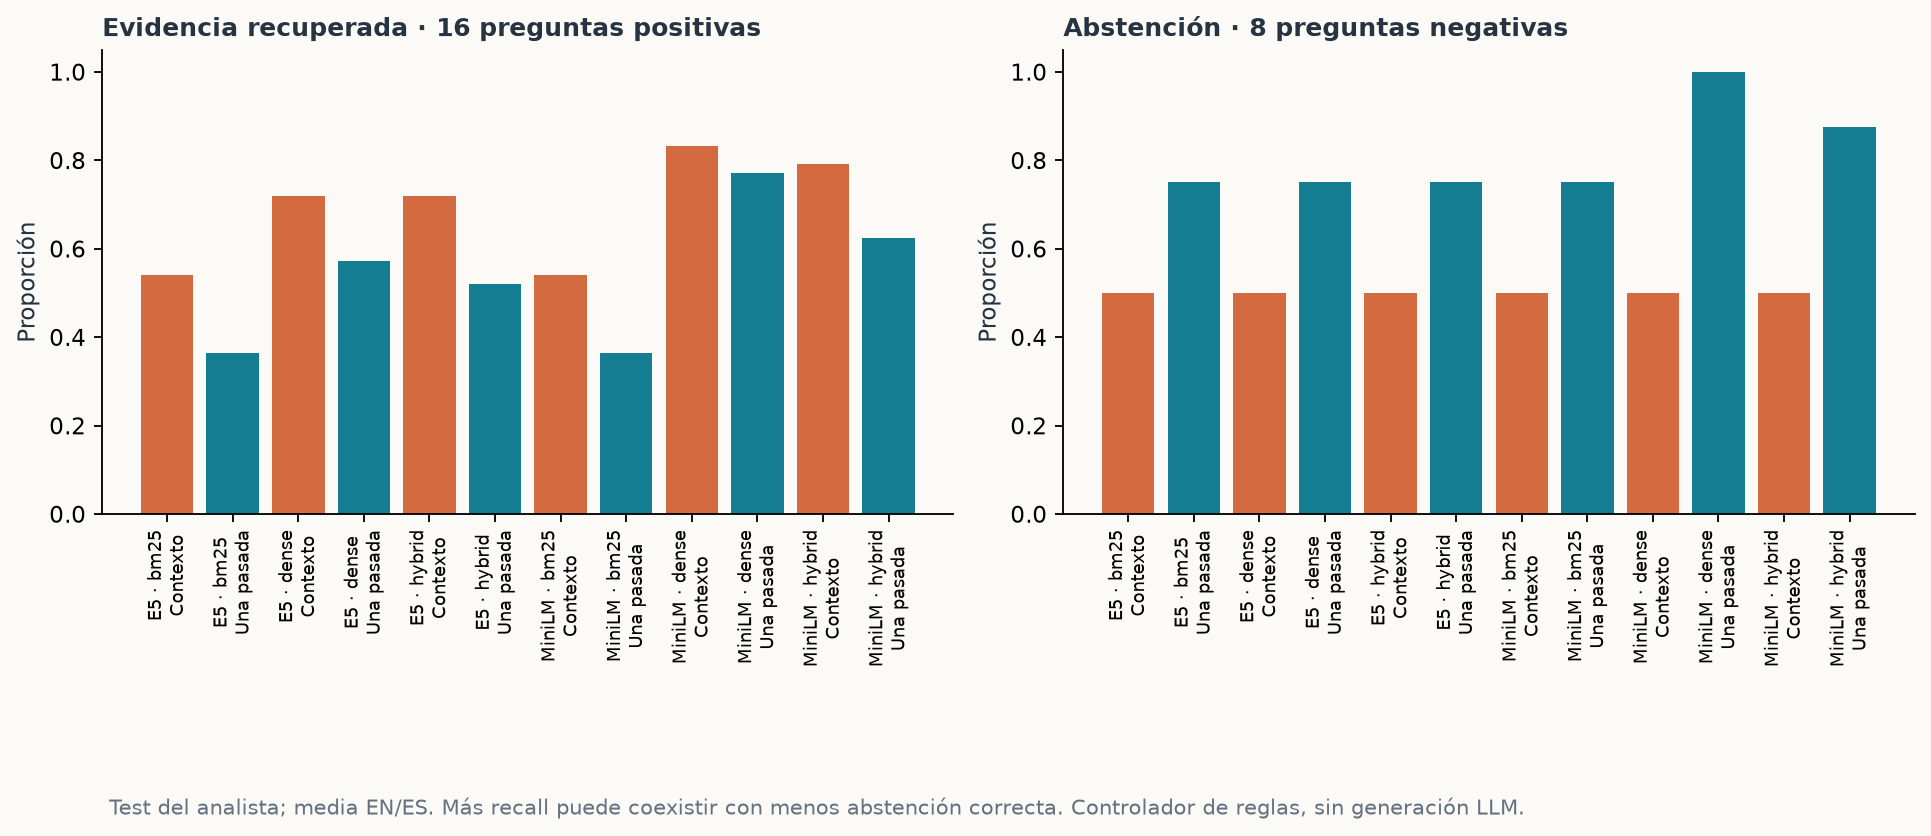

,model,method,metric,families,difference_contextual_minus_onepass,ci_low,ci_high,resamples,seed,scope
0,rag,bm25,recall_at_5,8,0.177083,0.041667,0.322917,5000,20261011,Paired conditional question-family bootstrap; ...
1,rag,bm25,context_support_recall,8,0.093750,-0.104167,0.322917,5000,20261011,Paired conditional question-family bootstrap; ...
2,rag,bm25,negative_safe_abstention,4,-0.250000,-0.500000,0.000000,5000,20261011,Paired conditional question-family bootstrap; ...
3,rag,dense,recall_at_5,8,0.062500,-0.020833,0.166667,5000,20261011,Paired conditional question-family bootstrap; ...
4,rag,dense,context_support_recall,8,0.114583,-0.145833,0.395833,5000,20261011,Paired conditional question-family bootstrap; ...
5,rag,dense,negative_safe_abstention,4,-0.500000,-1.000000,0.000000,5000,20261011,Paired conditional question-family bootstrap; ...
6,rag,hybrid,recall_at_5,8,0.166667,0.000000,0.312500,5000,20261011,Paired conditional question-family bootstrap; ...
7,rag,hybrid,context_support_recall,8,0.072917,-0.125000,0.312500,5000,20261011,Paired conditional question-family bootstrap; ...
8,rag,hybrid,negative_safe_abstention,4,-0.375000,-0.750000,0.000000,5000,20261011,Paired conditional question-family bootstrap; ...
9,rag-e5,bm25,recall_at_5,8,0.177083,0.052083,0.312500,5000,20261011,Paired conditional question-family bootstrap; ...


In [12]:
ragdir = RESULTS/'rag'
assert (ragdir/'summary.json').exists(), 'Ejecutar rag.py antes de publicar el notebook.'
rag = pd.concat([pd.read_csv(RESULTS/name/'summary.csv').assign(model=name) for name in ['rag','rag-e5']])
display(rag[rag.split=='test'][['model','method','arm','language','positive_queries','negative_queries','recall_at_5','context_support_recall','negative_safe_abstention_rate']])
display(Image(filename=str(STUDY/'figures/rag-recall-safety.png')))
display(pd.read_csv(RESULTS/'rag_family_sensitivity.csv'))

## 12. LangGraph y una extensión agentic sensible al contexto

El workflow ejecutado tiene estado y decisiones acotadas: enrutar alcance, recuperar, evaluar suficiencia, reformular como máximo dos veces, expandir contexto, devolver IDs o abstenerse y verificar pertenencia de citas. El controlador usa reglas y devuelve un paquete de evidencia, **no un análisis literario producido por un LLM**. Eso permite medir el enrutamiento sin atribuirle capacidades que no se ejecutaron.

La [documentación de LangGraph](https://docs.langchain.com/oss/python/langgraph/workflows-agents) distingue workflows de agentes que deciden dinámicamente herramientas y pasos. Para una extensión con LLM, los nodos de decisión deberían producir esquemas estructurados y dejar trazas de consulta, filtros, IDs, reformulaciones, consumo y motivo de abstención. El total de evidencia consumida debe incluir reintentos y vecinos; un contexto final pequeño no demuestra ahorro si antes se leyó el corpus entero.

[Self-RAG](https://arxiv.org/abs/2310.11511), [CRAG](https://arxiv.org/abs/2401.15884) y [Adaptive-RAG](https://arxiv.org/abs/2403.14403) son diseños de investigación distintos. Un ciclo de prompts no replica automáticamente sus entrenamientos ni sus resultados. La recuperación contextual de [Anthropic](https://www.anthropic.com/engineering/contextual-retrieval) añade contexto al fragmento antes de indexar; no equivale a expandir vecinos después de recuperar. Se pueden comparar como ablations, pero deben nombrarse por su mecanismo.

La ampliación propuesta mantiene dos índices: letras/versiones y fuentes históricas verificadas. Una consulta sobre qué expresa una voz usa el primero; una sobre publicación o listas usa el segundo. El generador debe enlazar cada afirmación con la evidencia de su índice, reconocer contralecturas y abstenerse ante inferencias sobre toda una década. Un juez automático sería otra medida falible, no el sustituto de una lectura humana.

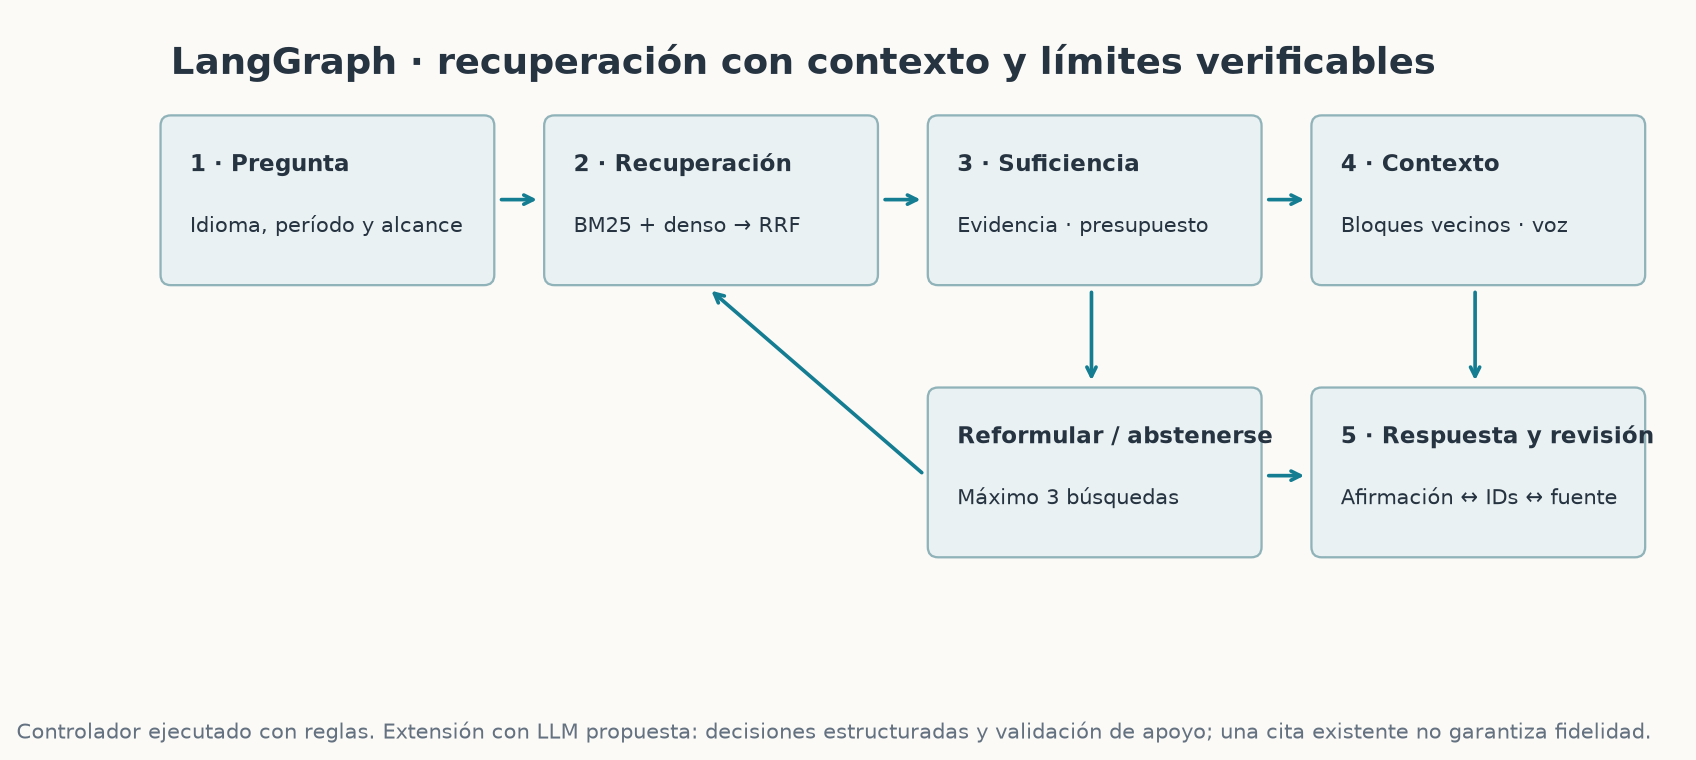

Implementación real: `rag.py`. Adaptador opcional de embeddings: `embed_api.py` (plan por defecto, sin red).

In [13]:
display(Image(filename=str(STUDY/'figures/langgraph-workflow.png')))
display(Markdown('Implementación real: `rag.py`. Adaptador opcional de embeddings: `embed_api.py` (plan por defecto, sin red).'))

## 12.1 Descomponer el contexto y revisar el apoyo con LLM

La descomposición posterior reformulación × vecinos mantiene rankings, gate y llamadas idénticos dentro de cada pareja de vecinos. Retirar vecinos mejora el recall de contexto denso de MiniLM de 0,479 a 0,583 y de E5 de 0,542 a 0,573: con cinco huecos disponibles, un vecino puede desplazar evidencia pertinente. Es una mejora exploratoria sobre las mismas familias, pendiente de un test nuevo.

La revisión con OpenAI recibe los contextos congelados de MiniLM híbrido, reformulación activa y vecinos desactivados. Separa respuesta apoyada, apoyo parcial e insuficiencia, preservando la pregunta original. Las referencias son propuestas del asistente, sin adjudicación humana: un desacuerdo no se convierte automáticamente en un error.

Anthropic recibe únicamente las veinte tripletas originales. No aporta embeddings ni analiza letras en esta fase. Sus etiquetas semánticas también pueden fallar: por ejemplo, temer una amenaza y disfrutar una actividad agradable no son proposiciones necesariamente incompatibles.

In [14]:
for name in ['rag-ablation','rag-e5-ablation']:
    table = pd.read_csv(RESULTS/name/'summary.csv')
    display(Markdown('### '+name+' · descomposición exploratoria'))
    display(table[table.split=='test'][['method','arm','language','recall_at_5','context_support_recall','negative_safe_abstention_rate']])
llmdir = RESULTS/'llm-review'
llm = read(llmdir/'summary.json')
display(pd.DataFrame([r for r in llm['review'] if r['requested']>0]))
display(pd.DataFrame(read(llmdir/'anthropic-synthetic.json'))[['probe_id','category','relationship_ab','relationship_ac','status']])
labels = read(RESULTS/'topic_labels.json')
display(pd.DataFrame(labels)[['model_id','topic_id','label','interpretation','status']])
display(read(RESULTS/'provider-api-status.json'))

### rag-ablation · descomposición exploratoria

,method,arm,language,recall_at_5,context_support_recall,negative_safe_abstention_rate
2,bm25,rewrite_0_neighbors_0,en,0.312500,0.312500,0.75
3,bm25,rewrite_0_neighbors_0,es,0.416667,0.416667,0.75
6,bm25,rewrite_0_neighbors_1,en,0.312500,0.333333,0.75
7,bm25,rewrite_0_neighbors_1,es,0.416667,0.333333,0.75
10,bm25,rewrite_1_neighbors_0,en,0.479167,0.312500,0.50
11,bm25,rewrite_1_neighbors_0,es,0.604167,0.604167,0.50
14,bm25,rewrite_1_neighbors_1,en,0.479167,0.333333,0.50
15,bm25,rewrite_1_neighbors_1,es,0.604167,0.583333,0.50
18,dense,rewrite_0_neighbors_0,en,0.812500,0.437500,1.00
19,dense,rewrite_0_neighbors_0,es,0.729167,0.291667,1.00


### rag-e5-ablation · descomposición exploratoria

,method,arm,language,recall_at_5,context_support_recall,negative_safe_abstention_rate
2,bm25,rewrite_0_neighbors_0,en,0.312500,0.312500,0.75
3,bm25,rewrite_0_neighbors_0,es,0.416667,0.416667,0.75
6,bm25,rewrite_0_neighbors_1,en,0.312500,0.333333,0.75
7,bm25,rewrite_0_neighbors_1,es,0.416667,0.333333,0.75
10,bm25,rewrite_1_neighbors_0,en,0.479167,0.312500,0.50
11,bm25,rewrite_1_neighbors_0,es,0.604167,0.604167,0.50
14,bm25,rewrite_1_neighbors_1,en,0.479167,0.333333,0.50
15,bm25,rewrite_1_neighbors_1,es,0.604167,0.583333,0.50
18,dense,rewrite_0_neighbors_0,en,0.625000,0.583333,0.75
19,dense,rewrite_0_neighbors_0,es,0.520833,0.333333,0.75


,provider,model,requested,valid_reviews,status_counts,positive_queries,negative_queries,positive_abstentions,positive_complete_contexts,complete_context_abstentions,positive_incomplete_contexts,incomplete_context_abstentions,negative_safe_abstentions,invalid_citation_reviews,accounted_usd,limitation
0,openai,gpt-5.4-mini,24,24,{'executed': 24},16,8,8,8,1,8,7,8,0,0.020694,Comparison to assistant provisional absence/su...


,probe_id,category,relationship_ab,relationship_ac,status
0,negation_en,negation,contradiction,unrelated,executed
1,negation_es,negation,contradiction,unrelated,executed
2,role_en,role_reversal,role_reversal,related_not_equivalent,executed
3,role_es,role_reversal,role_reversal,related_not_equivalent,executed
4,translation_en_es,crosslingual,equivalent,contradiction,executed
5,translation_es_en,crosslingual,equivalent,contradiction,executed
6,context_en,fear_context,related_not_equivalent,related_not_equivalent,executed
7,context_es,fear_context,related_not_equivalent,related_not_equivalent,executed
8,repetition_en,repetition,equivalent,contradiction,executed
9,repetition_es,repetition,equivalent,contradiction,executed


,model_id,topic_id,label,interpretation,status
0,sentence-transformers/paraphrase-multilingual-...,0,Temor al abandono amoroso,"Voz íntima que expresa miedo, pérdida y deseng...",llm_hypothesis_unvalidated
1,sentence-transformers/paraphrase-multilingual-...,1,Tensión nocturna y deseo,Voces que enfrentan una noche inquietante o in...,llm_hypothesis_unvalidated
2,sentence-transformers/paraphrase-multilingual-...,2,Inseguridad y autojuicio,"Voces que se sienten observadas, fuera de luga...",llm_hypothesis_unvalidated
3,sentence-transformers/paraphrase-multilingual-...,3,Vocalizaciones sin palabras,"Voces repetitivas y expresivas, sin objeto cla...",llm_hypothesis_unvalidated
4,sentence-transformers/paraphrase-multilingual-...,4,Huida hacia lo oscuro,Voces en primera o segunda persona describen e...,llm_hypothesis_unvalidated
5,sentence-transformers/paraphrase-multilingual-...,5,Celebración y autosuficiencia,Voces festivas o afirmativas celebran ánimo al...,llm_hypothesis_unvalidated
6,sentence-transformers/paraphrase-multilingual-...,6,"Noches, deseo y presagios","Voces femeninas o íntimas atraviesan noche, de...",llm_hypothesis_unvalidated
7,sentence-transformers/paraphrase-multilingual-...,7,"Baile, alegría y cercanía","Voces festivas buscan compañía, baile y disfru...",llm_hypothesis_unvalidated
8,sentence-transformers/paraphrase-multilingual-...,8,Dolor amoroso y desahogo,Voz lírica que afronta pérdida afectiva con la...,llm_hypothesis_unvalidated
9,sentence-transformers/paraphrase-multilingual-...,9,"Madre, culpa y desafío",Voces dirigidas a una madre o figura materna e...,llm_hypothesis_unvalidated


{'authorized_destinations': ['OpenAI', 'Gemini/GCP'],
 'budget_ceiling_usd': 1,
 'google': {'credentials_metadata_status': 200,
  'models_attempted': ['gemini-embedding-2', 'gemini-embedding-001'],
  'inference_http_status': 402,
  'error_status': 'RESOURCE_EXHAUSTED',
  'failure_category': 'billing_payment_credit',
  'vectors_received': 0,
  'note': 'Authentication permits model listing; inference rejected. No account or billing changes made.'},
 'anthropic': {'key_variable_alias': 'ANTROPIC_API_KEY',
  'raw_corpus_sent': False,
  'planned_scope': 'Original synthetic probes only; Anthropic offers no native embedding model.'}}

**Conclusiones observadas.** OpenAI se abstuvo en 8/8 negativas y en 8/16 positivas. Entre ocho contextos positivos que contenían todos los IDs de apoyo anotados provisionalmente, sólo uno recibió abstención; entre ocho con apoyo incompleto, siete recibieron abstención. La recuperación y el lector necesitan evaluaciones separadas.

No hubo citas fuera del contexto; eso no valida por sí solo apoyo semántico. Anthropic distinguió las dos negaciones y las dos inversiones de roles, pero marcó como contradicciones dos contrastes de actividades compatibles. Un revisor LLM necesita una auditoría del tipo de relación que está afirmando.

OpenAI embedding 3 large produjo 11 tópicos y 14 márgenes favorables en 14 preferencias sintéticas previstas, con ARI de semillas 0,942–0,946. Su NMI tópico–idioma, 0,508, mantiene un factor de confusión relevante. Una mejora en esas medidas no confirma mejores categorías históricas ni una detección de miedo validada.

## 13. Conclusiones que deben sobrevivir a la revisión

El corpus puede mostrar relaciones entre motivos y límites de encoders. No puede identificar cambios históricos generales de la experiencia del miedo. Las diferencias entre proveedores afectan la medida antes del modelo; las diferencias entre encoders afectan las particiones antes de la interpretación.

Un resultado negativo también informa: un final truncado, una inversión de roles que conserva cercanía, un tópico concentrado en un artista o un controlador que no mejora recall obligan a cambiar el diseño. No se eliminan para cerrar una historia convincente.

Para una fase confirmatoria: definir mercados y marcos de muestreo; ampliar canciones por año y artista; anotar voces, negación, objeto, postura y eventos con lectores EN/ES independientes; medir desacuerdo; validar por canción/artista fuera de muestra; comparar proveedores con consultas y presupuestos idénticos; agregar audio solo con una pregunta que requiera sonido. El desacuerdo interpretativo debe conservarse como parte del objeto de estudio.

In [15]:
# Comprobaciones del informe: corpus común, estados reales y salidas sin letras.
assert all(read(p/'model_manifest.json')['results_status'] == 'executed' for p in modeldirs)
assert diag['songs_with_lyrics'] == 40
assert set(manifest.language) == {'en','es'}
for directory in modeldirs:
    composition = pd.read_csv(directory/'decade_composition.csv')
    sums = composition.groupby(['variant','decade','language']).song_normalized_share.sum()
    assert np.allclose(sums, 1), 'Las proporciones no conservan el denominador.'
    print(directory.name, '✓ proporciones y recibo de ejecución')
print('Verificación del cuaderno completada. Revisar también source-audit.json y editorial-audit.md.')

intfloat--multilingual-e5-small ✓ proporciones y recibo de ejecución
openai--text-embedding-3-large ✓ proporciones y recibo de ejecución
sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2 ✓ proporciones y recibo de ejecución
Verificación del cuaderno completada. Revisar también source-audit.json y editorial-audit.md.
